In [1]:
import matplotlib.pyplot as plt
from dstools.dynamic_spectrum import DynamicSpectrum, LightCurve
from dstools.plotting import plot_ds, plot_lightcurve
import os
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Rectangle
import astropy.constants as c
import astropy.units as u
from scipy.optimize import curve_fit


We want to analyse our burst in the radio to see what sort of properties we can get out of it. The first thing I want to calculate is the brightness temperature. To do that, we need a measure of the flux of the burst.

Let's start by loading in our burst

In [349]:
vis_path = Path('../visibility_files/')
ds_files = list(vis_path.rglob('*.ds'))

In [352]:
# 55363, 62276, 62277
matches = [p for p in ds_files if "tyc_89" in str(p)]

In [353]:
matches

[PosixPath('../visibility_files/tyc_8927-1888-1/22333/tyc_8927_22333.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/36208/tyc_8927_36208.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/39406/tyc_8927_39406.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/57060/tyc_8927_57060.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/67961/tyc_8927_67961.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/54101/tyc_8927_54101.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/75575/tyc_8927_75575.ds'),
 PosixPath('../visibility_files/tyc_8927-1888-1/8678/tyc_8927_8678.ds')]

In [354]:
ds = DynamicSpectrum(ds_path=matches[5])

In [355]:
max(ds.time) + np.median(np.diff(ds.time)) 

np.float64(9.991987199988216)

In [326]:
0.19077120028669015 * 60

11.446272017201409

In [327]:
np.mean(ds.freq)

np.float64(1017.9907407407362)

In [329]:
ds.freq

array([ 890.99074074,  891.99074074,  892.99074074,  893.99074074,
        894.99074074,  895.99074074,  896.99074074,  897.99074074,
        898.99074074,  899.99074074,  900.99074074,  901.99074074,
        902.99074074,  903.99074074,  904.99074074,  905.99074074,
        906.99074074,  907.99074074,  908.99074074,  909.99074074,
        910.99074074,  911.99074074,  912.99074074,  913.99074074,
        914.99074074,  915.99074074,  916.99074074,  917.99074074,
        918.99074074,  919.99074074,  920.99074074,  921.99074074,
        922.99074074,  923.99074074,  924.99074074,  925.99074074,
        926.99074074,  927.99074074,  928.99074074,  929.99074074,
        930.99074074,  931.99074074,  932.99074074,  933.99074074,
        934.99074074,  935.99074074,  936.99074074,  937.99074074,
        938.99074074,  939.99074074,  940.99074074,  941.99074074,
        942.99074074,  943.99074074,  944.99074074,  945.99074074,
        946.99074074,  947.99074074,  948.99074074,  949.99074

In [328]:
(np.max(ds.freq) - np.min(ds.freq)) + np.median(np.diff(ds.freq))

np.float64(254.9999999999934)

In [47]:
tavg=50
favg=1
ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=favg)
lc = LightCurve(ds)

In [48]:
ds.freq

array([ 799.99074074,  800.99074074,  801.99074074,  802.99074074,
        803.99074074,  804.99074074,  805.99074074,  806.99074074,
        807.99074074,  808.99074074,  809.99074074,  810.99074074,
        811.99074074,  812.99074074,  813.99074074,  814.99074074,
        815.99074074,  816.99074074,  817.99074074,  818.99074074,
        819.99074074,  820.99074074,  821.99074074,  822.99074074,
        823.99074074,  824.99074074,  825.99074074,  826.99074074,
        827.99074074,  828.99074074,  829.99074074,  830.99074074,
        831.99074074,  832.99074074,  833.99074074,  834.99074074,
        835.99074074,  836.99074074,  837.99074074,  838.99074074,
        839.99074074,  840.99074074,  841.99074074,  842.99074074,
        843.99074074,  844.99074074,  845.99074074,  846.99074074,
        847.99074074,  848.99074074,  849.99074074,  850.99074074,
        851.99074074,  852.99074074,  853.99074074,  854.99074074,
        855.99074074,  856.99074074,  857.99074074,  858.99074

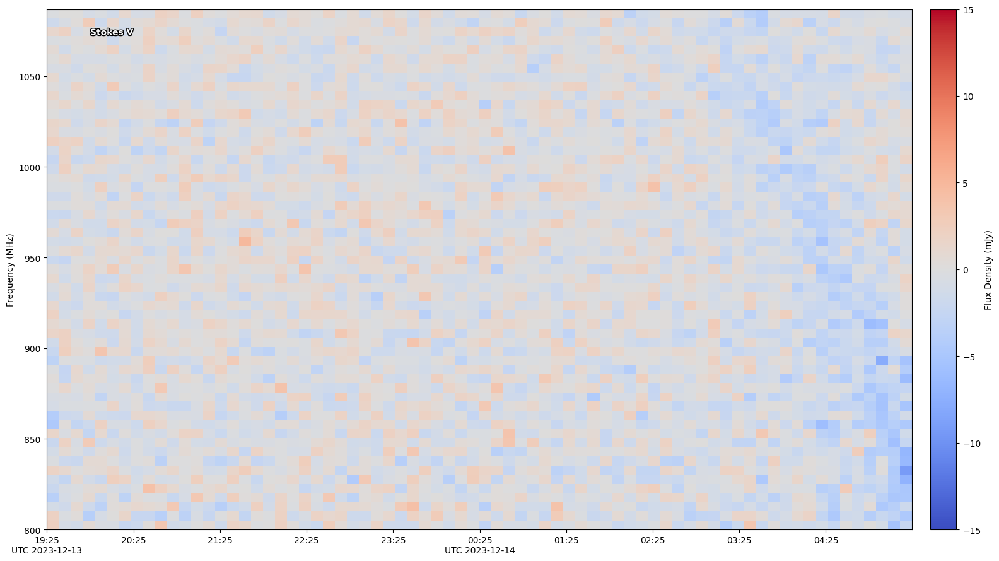

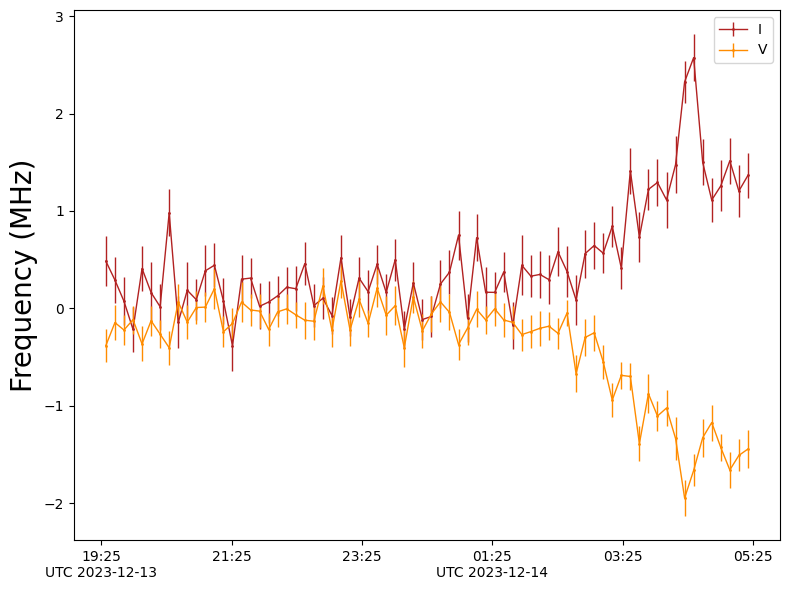

In [5]:
fig, ax = plt.subplots(1,1, figsize=(16,9))

plot_ds(ds, stokes='V', cmax=15, imag=False, fig=fig, ax=ax)
plot_lightcurve(lc, stokes = 'IV')

ax = fig.axes[0]
ax.set_aspect('auto')
plt.ylabel('Frequency (MHz)', fontsize=20)
plt.tight_layout()

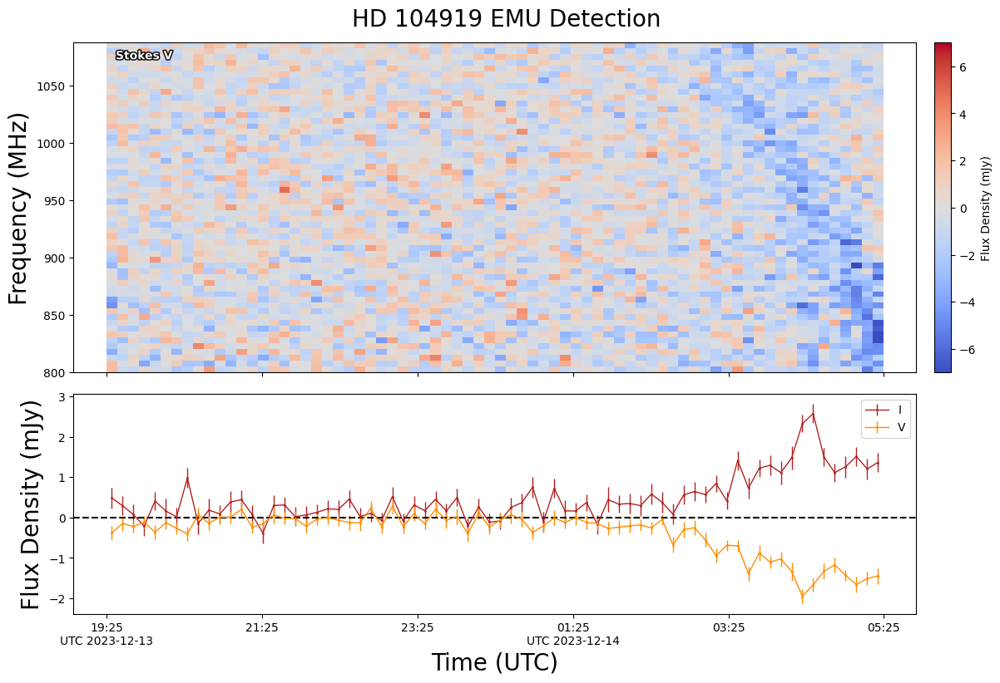

In [15]:
fig, (ax_ds, ax_lc) = plt.subplots(
    2, 1,
    figsize=(12, 8),
    height_ratios=[3, 2],
    sharex=True
)

plot_ds(ds, stokes='V', cmax=7, imag=False, fig=fig, ax=ax_ds)
plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax_lc)
ax_lc.axhline(0, c = 'black', ls = '--')

fig.suptitle('HD 104919 EMU Detection', fontsize=20)
plt.tight_layout()

ax_ds.set_aspect('auto')

# Get the DS position after plot_ds has added the colourbar
ds_pos = ax_ds.get_position()
lc_pos = ax_lc.get_position()

# Force LC to have exactly the same horizontal extent as DS
ax_lc.set_position([
    ds_pos.x0,
    lc_pos.y0,
    ds_pos.width,
    lc_pos.height
])

ax_ds.set_ylabel('Frequency (MHz)', fontsize=20)
ax_lc.set_ylabel('Flux Density (mJy)', fontsize=20)
ax_lc.set_xlabel('Time (UTC)',fontsize=20)

plt.show()

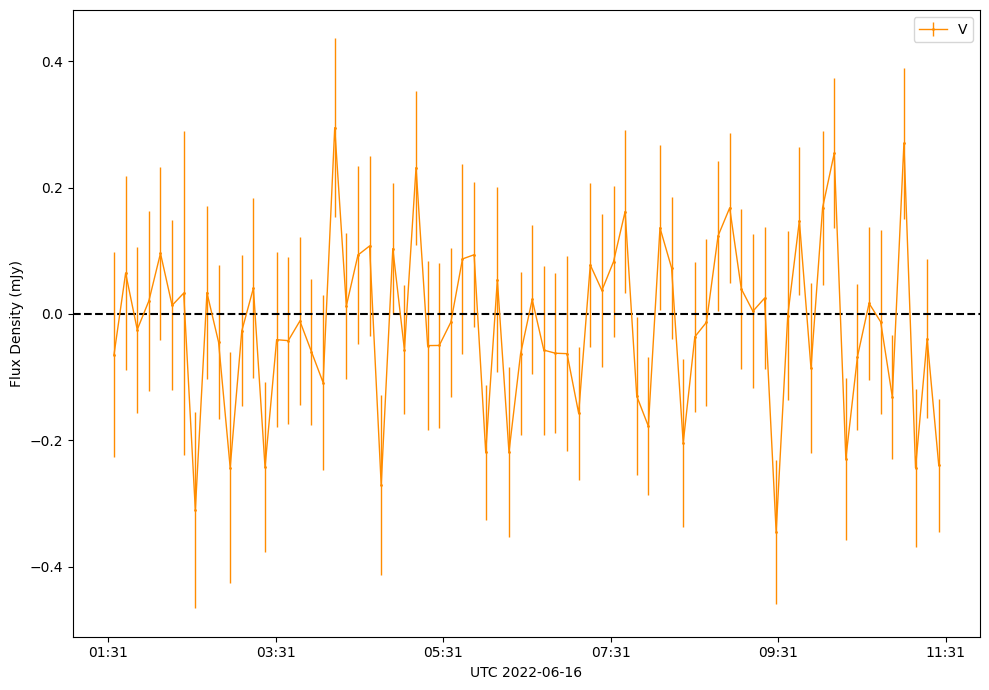

In [28]:
fig, ax = plt.subplots(figsize=(10, 7))

plot_lightcurve(lc, stokes='V', ax=ax, fig=fig)

ax.axhline(0, ls='--', c='black')

Text(0.5, 1.0, 'Lightcurve for HD 104919 Burst')

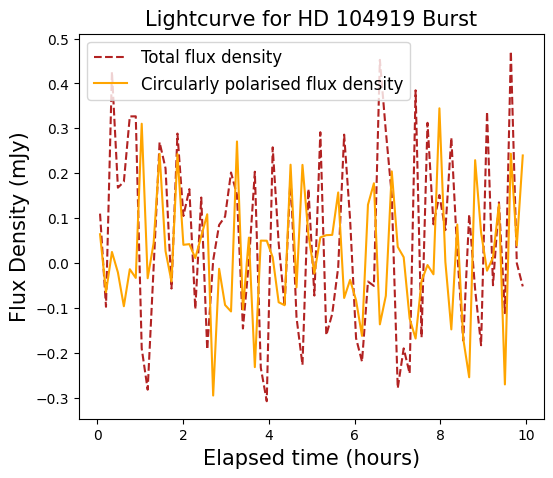

In [30]:
plt.figure(figsize = (6,5))
plt.plot(lc.time, lc.flux['I'], ls = '--', c = 'firebrick', label = 'Total flux density')
plt.plot(lc.time, -1*lc.flux['V'], c = 'orange', label = 'Circularly polarised flux density')
plt.xlabel('Elapsed time (hours)', fontsize=15)
plt.ylabel('Flux Density (mJy)', fontsize=15)
plt.legend(loc = 'upper left', fontsize=12)
plt.title('Lightcurve for HD 104919 Burst',fontsize=15)

(<Figure size 800x600 with 2 Axes>, <Axes: ylabel='Frequency (MHz)'>)

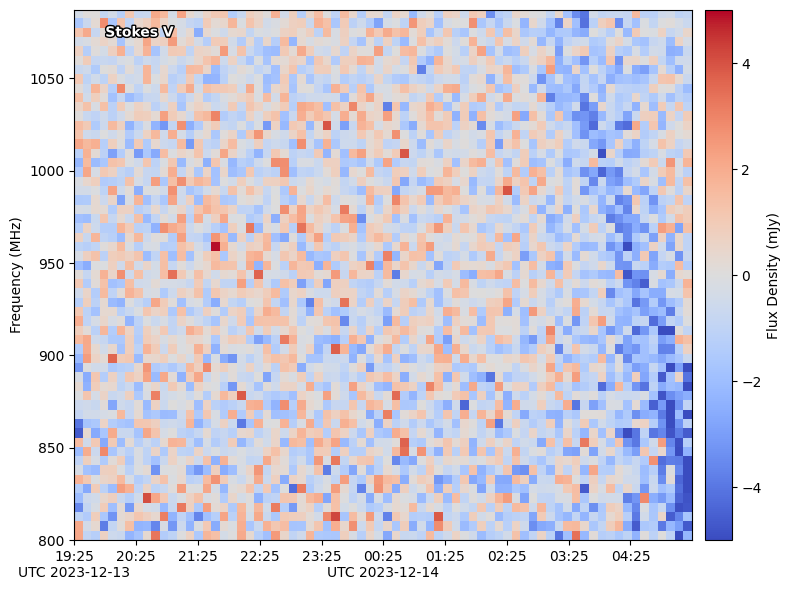

In [77]:
plot_ds(ds, stokes='V', cmax=5)

In [46]:
ds.freq

array([ 802.02199074,  807.07407407,  812.12615741,  817.17824074,
        822.23032407,  827.28240741,  832.33449074,  837.38657407,
        842.43865741,  847.49074074,  852.54282407,  857.59490741,
        862.64699074,  867.69907407,  872.75115741,  877.80324074,
        882.85532407,  887.90740741,  892.95949074,  898.02199074,
        903.07407407,  908.12615741,  913.17824074,  918.23032407,
        923.28240741,  928.33449074,  933.38657407,  938.43865741,
        943.49074074,  948.54282407,  953.59490741,  958.64699074,
        963.69907407,  968.75115741,  973.80324074,  978.85532407,
        983.90740741,  988.95949074,  994.02199074,  999.07407407,
       1004.12615741, 1009.17824074, 1014.23032407, 1019.28240741,
       1024.33449074, 1029.38657407, 1034.43865741, 1039.49074074,
       1044.54282407, 1049.59490741, 1054.64699074, 1059.69907407,
       1064.75115741, 1069.80324074, 1074.85532407, 1079.90740741,
       1084.95949074])

We can then plot it again just to check that we know what we are working with here.

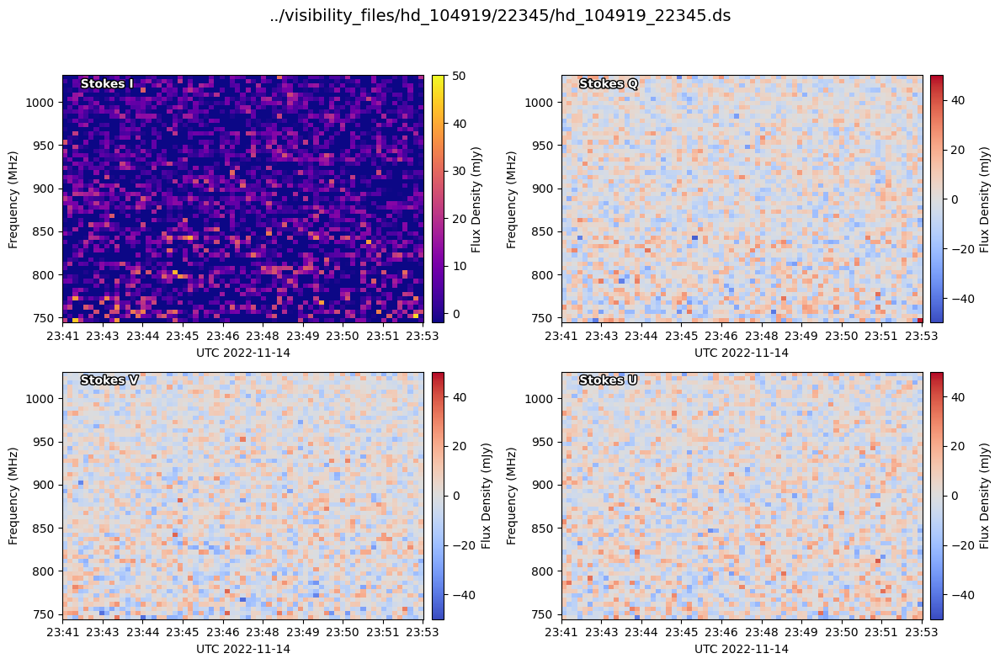

In [20]:
tavg=1
favg=5
ds = DynamicSpectrum(ds_path=matches[3],tavg=tavg, favg=favg)
lc = LightCurve(ds)
cmax_val = 50

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 0])

plot_ds(ds, stokes='Q', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 1])

plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 0])

plot_ds(ds, stokes='U', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 1])

fig.suptitle(f'{str(matches[0])}', fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

(<Figure size 800x600 with 1 Axes>, <Axes: ylabel='Flux Density (mJy)'>)

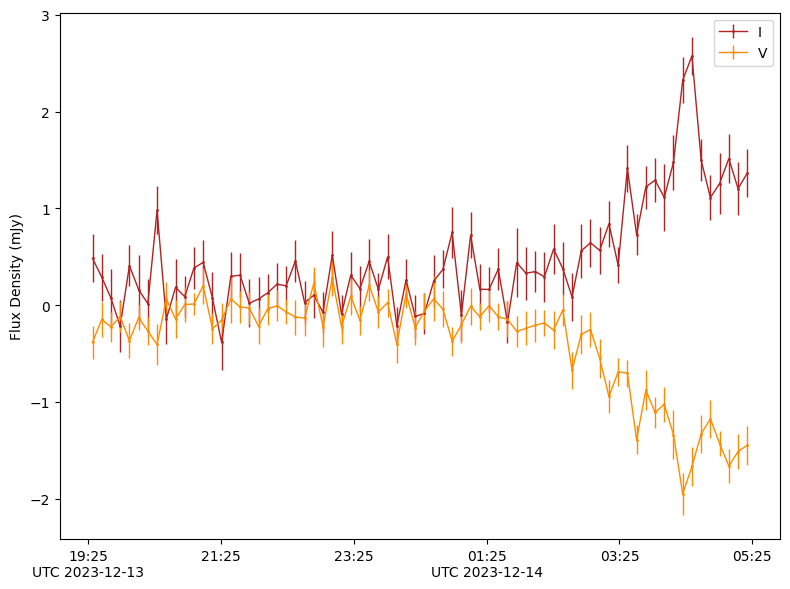

In [183]:
plot_lightcurve(lc, stokes = 'IV')

# Peak flux measurements

Perhaps the most naive approach would be to simply take the peak flux from the lightcurve. This would yield us a peak flux of ~2.5mJy

In [16]:
lc_flux = np.max(lc.flux['I'])

In [17]:
lc_flux

np.float64(2.5744309196131616)

Another naive approach would just be to take the brightest pixel.

In [19]:
flux_arr = np.real(ds.data['I'].flatten())

In [20]:
flux_peak = np.max(flux_arr)

We could also simply do a 3 sigma cut (note a 5 sigma cut only gives 2 data points) and take the average for a more robust statistic.

In [21]:
stdev = np.nanstd(flux_arr)
mean = np.nanmean(flux_arr)

In [27]:
flux_sig = np.mean(flux_arr[flux_arr > mean + 3*stdev])
flux_sig_err = np.std(flux_arr[flux_arr > mean + 3*stdev])

In [28]:
flux_sig_err

np.float64(0.9443124534892734)

Since we are doing order of magnitude calculations anyway for brightness temperature, it is likely that these are fine choices, which already agree to an order of magnitude (1-10mJy, likely on the higher end).

In [23]:
print(lc_flux)
print(flux_peak)
print(flux_sig)

2.5744309196131616
9.854108885109971
7.165793990892889


# Burst SNR Map

It also helps to visualise just how weak our detection here is. The majority of points don't even meet a 1 sided SNR of 3.

In [190]:
noise = np.nanstd(np.real(ds.data['V'][:30]))
snr_map = np.real(ds.data['V']) / noise

In [191]:
mask = snr_map < -3

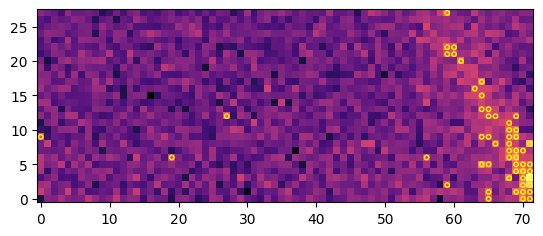

In [192]:
x,y = np.where(mask)

plt.imshow(np.real(ds.data['V']).T, origin='lower', cmap='magma_r')
plt.scatter(x, y, s=10, facecolors='none', edgecolors='yellow')

In [193]:
np.shape(ds.data['V'])

(72, 28)

# Brightness temp

Assuming the entire surface of the star is the emitting region (a lower bound), our formula for the brightness temperature should be:

$$ T_b \approx \frac{c^2}{2k_b\nu^2} \frac{S_{\nu}D^2}{\pi R_*^2}$$

In [34]:
nu = 943 * u.MHz
flux = flux_sig * u.mJy
dist = 	100.93083190917969 * u.pc

In [33]:
ds.header

{'dstools_version': '2.0.0',
 'telescope': 'ASKAP',
 'datacolumn': 'DATA',
 'feeds': 'linear',
 'antennas': np.int64(36),
 'baselines': np.int64(630),
 'integrations': 3615,
 'channels': 288,
 'polarisations': np.int64(4),
 'correlations': np.int64(1749265943040),
 'phasecentre': '12h04m48.769152s -64d09m55.489968s',
 'pb_scale': np.int64(1),
 'time_start': '2023-12-13 19:25:37.754',
 'time_scale': 'utc',
 'time_resolution': '499.729 s',
 'freq_resolution': '5.05 MHz'}

In [43]:
Tb = (c.c**2) / (2 * c.k_B * nu**2) * (flux * dist**2) / (np.pi * (0.136*c.R_sun)**2)

In [44]:
Tb.to(u.K)

<Quantity 9.0457829e+13 K>

Even with an underestimation of emission region size, we are still looking at a coherent emitter, which lines up with our high circular polarisation fractions and ~ hour long burst.

# Fitting the burst

Let's start by trying to figure out what the drift rate of the burst is. If this was plasma emission, we would expect a linear fit to be best, but ECMI would follow a different relation, so let's fit a power law and see what we get out.

First, let's get our data. If we use our SNR map from earlier, we have the pulse quite clearly defined, but I also want to try changing the amount of filtering to see how that affects our results. We need to make a mask to make sure we only get the data that contains our pulse, cutting to the last part of our data.

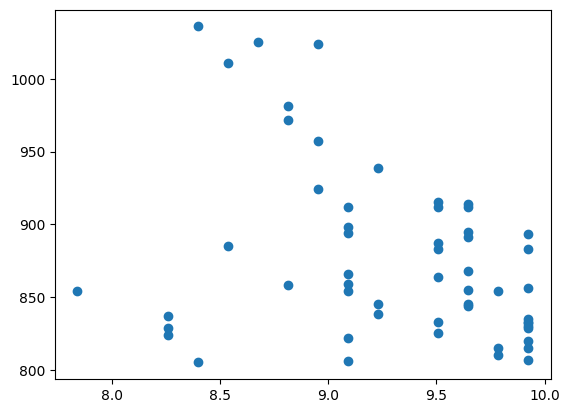

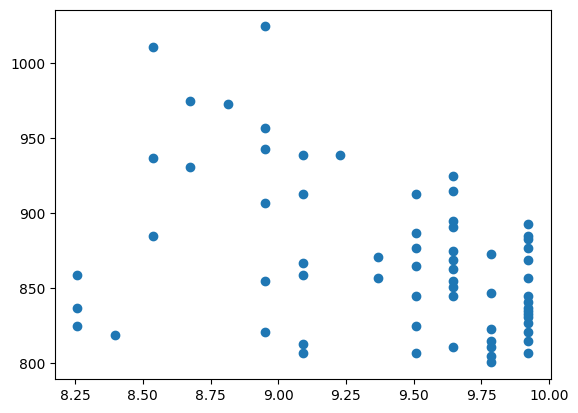

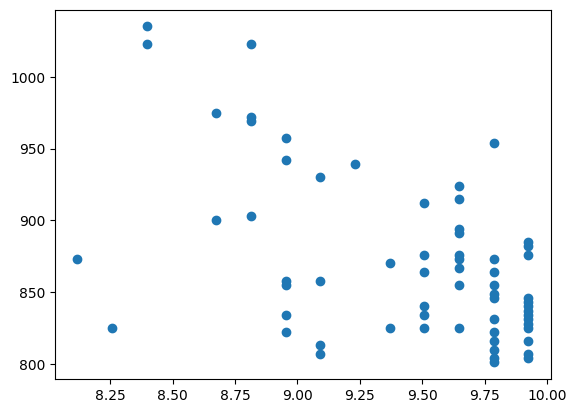

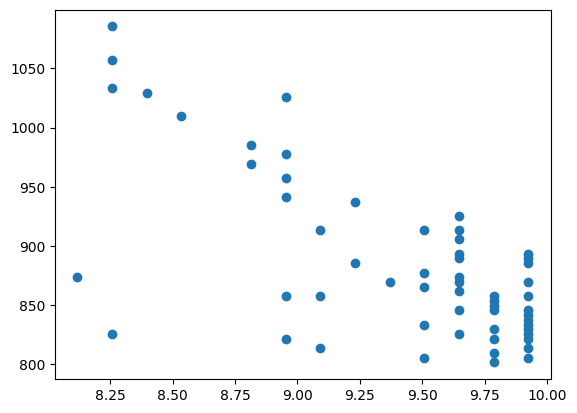

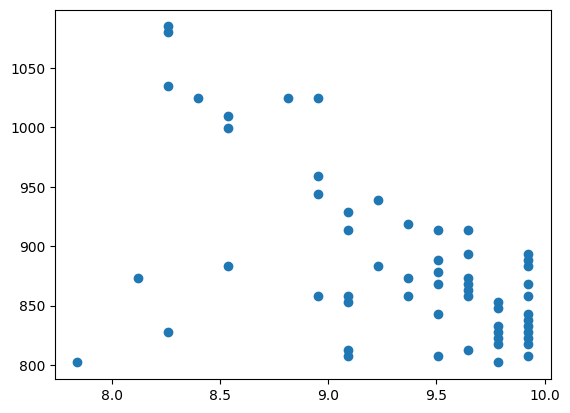

In [197]:
# To change the filtering
f_vals = [1,2,3,4,5]

for f in f_vals:
    # Create our DS
    ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=f)

    # Create our noise map
    noise = np.nanstd(np.real(ds.data['V'][:30]))
    snr_map = np.real(ds.data['V']) / noise
    mask = snr_map < -3

    # Extract our time/freq grid
    T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
    t_vals = T[mask]
    f_vals = F[mask]

    # Add an extra criteria, burst only occurs at the end of the observation
    t_mask = t_vals > 7.5
    t_vals = t_vals[t_mask]
    f_vals = f_vals[t_mask]

    plt.scatter(t_vals, f_vals)
    plt.show()
    plt.close()
    

From this, we can see that we don't get a super clear burst without quite a bit of filtering. We also run into the problem of wanting to find the burst ToA rather than just all points with a high SNR. For these reasons, lets work with the burst where favg=5, i.e. 5MHz bandwidth per sample.

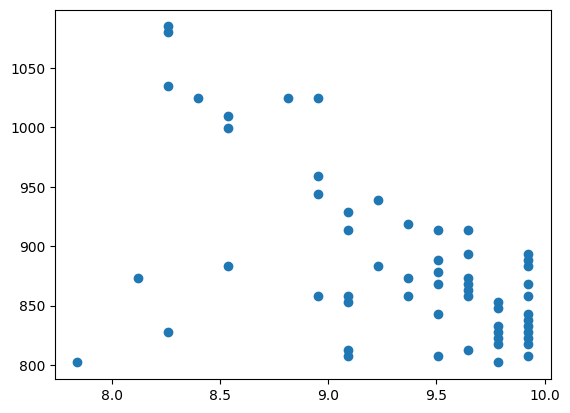

In [198]:
plt.scatter(t_vals, f_vals)

The most robust way I can think of to remove the rest of the outliers is to do a naive fit and look for extreme outliers. i.e. which points don't roughly align with the trend. Let's start by creating an array of the first incoming data points for a given frequency

In [199]:
def linear(t, a, b):
    return a * t + b

In [200]:
order = np.argsort(t_vals)
t_fit = t_vals[order]
nu_fit = f_vals[order]

In [201]:
nu_first = []
t_first = []
for freq in np.unique(nu_fit):
    freq_mask = nu_fit == freq
    times = t_fit[freq_mask]
    nu_first.append(freq)
    t_first.append(times[0])

t_first = np.array(t_first)
nu_first = np.array(nu_first)

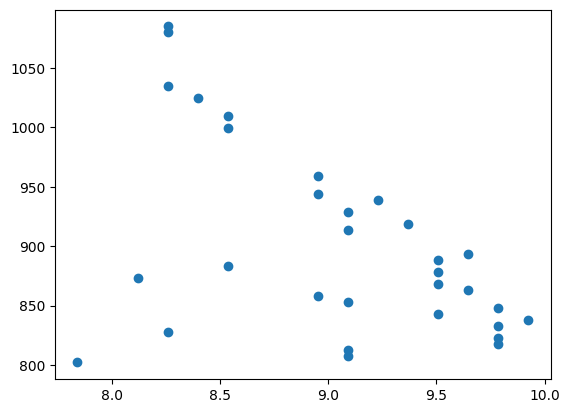

In [202]:
plt.scatter(t_first, nu_first)

Now it is clear we still have some outliers that are not part of our burst, let's iteratively sigma clip them until we are happy with what we are left with.

In [203]:
def sigma_clip(nu, t, plot=True, sig=2):

    # Fit the model
    popt, pcov = curve_fit(linear, t, nu)
    a, b = popt

    # Calculate the residuals
    nu_model = linear(t, a, b)
    residuals = nu - nu_model
    sigma = np.std(residuals)
    mask = residuals < -sig*sigma

    if plot == True:
        plt.scatter(t, nu)
        plt.scatter(t[mask], nu[mask], c='red')
        plt.show()
        plt.close()

    return nu[~mask], t[~mask], np.sum(mask)

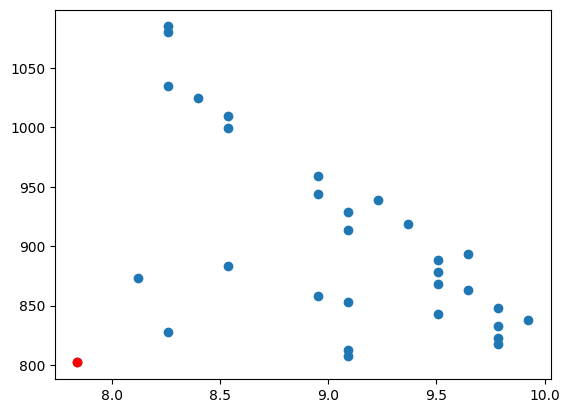

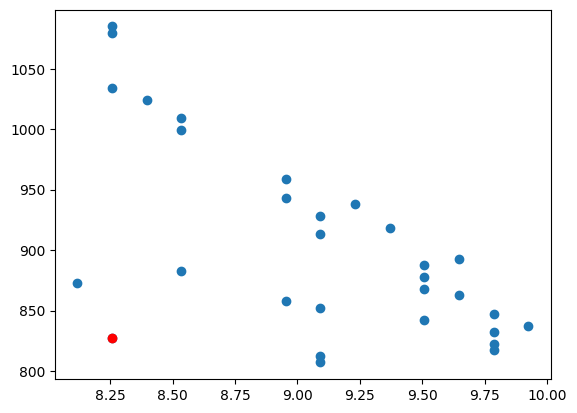

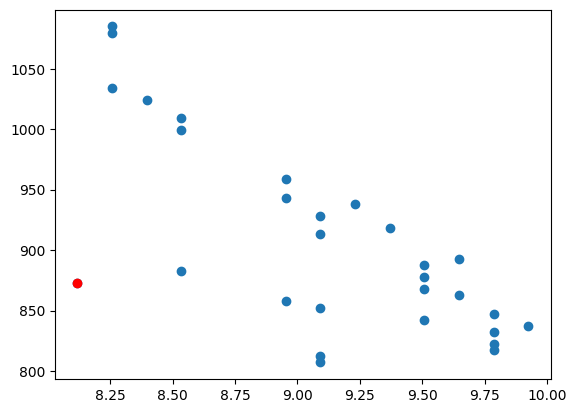

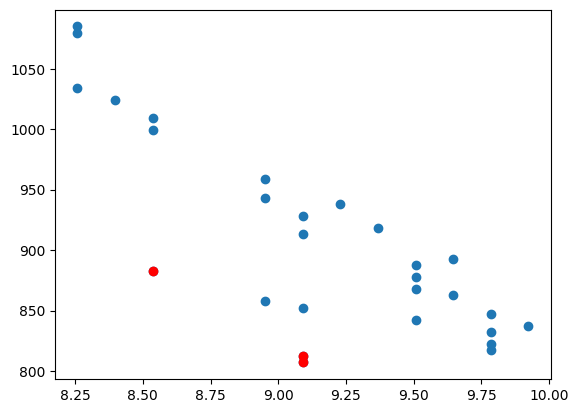

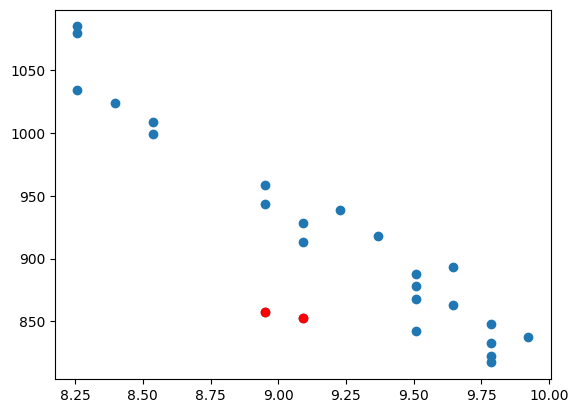

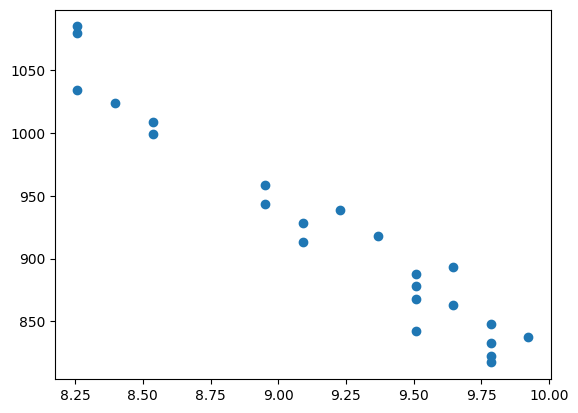

In [204]:
nu, t = nu_first, t_first
for i in range(0,10): # to ensure we dont go on forever
    nu, t, mask_sum = sigma_clip(nu, t)
    if mask_sum == 0:
        break

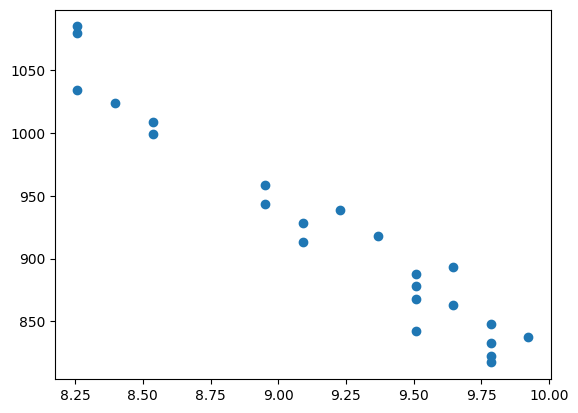

In [205]:
plt.scatter(t, nu)

So if we are to believe that our method works, we should see it agree with our burst when overplotted on the DS

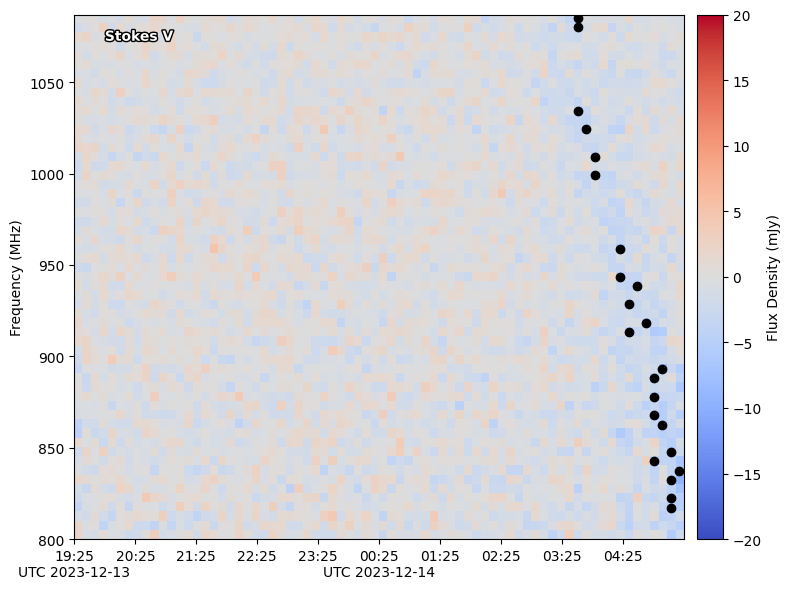

In [206]:
plot_ds(ds, stokes='V')
plt.scatter(t, nu, c = 'black')

And to it's credit, it appears to have done so quite well. Next, we need to fit our physical relations to this data. That is, a power law for ECMI, and an exponential for Plasma

## Plasma emission

For plasma emission, we know $\nu \propto \sqrt{n_e}$. We also know that in Hydrostatic equilibrium, $\frac{dP}{dr} \propto -\rho \propto -n_e$, giving us 

$$ n_e(r) = n_0e^{-r/H}$$

Where H is our characteristic scale height. Since $\nu(r) \propto \sqrt{n_e(r)}$, and assuming some linear propagation of plasma such that $r = vt$, we find that

$$\nu(t) = \nu_o'e^{vt/2H}$$

For fitting convenience, define $\alpha = v/2H$

In [207]:
def exp_model(t, nu0, v_over_H, t0):
    return nu0 * np.exp(-(v_over_H/2.0) * (t - t0))

In [208]:
p0 = [np.max(nu),1,np.min(t)]
popt, pcov = curve_fit(exp_model, t, nu, p0=p0, maxfev=10000)
nu0_fit, v_over_H_fit, t0_fit = popt

In [209]:
perr = np.sqrt(np.diag(pcov))

nu0_err, v_over_H_err, t0_err = perr

print(f"nu_0  = {nu0_fit:.3f} ± {nu0_err:.3f}")
print(f"v/H = {v_over_H_fit:.3f} ± {v_over_H_err:.3f}")
print(f"t_0  = {t0_fit:.3f} ± {t0_err:.3f}")

nu_0  = 37425.229 ± 23542130686.628
v/H = 0.301 ± 0.016
t_0  = -15.404 ± 4173689.039


Now try and plot it over our DS.

In [210]:
t_plot = np.linspace(t.min(), t.max(), 500) # Interpolate over a smooth grid
nu_plot = exp_model(t_plot, nu0_fit, v_over_H_fit, t0_fit)

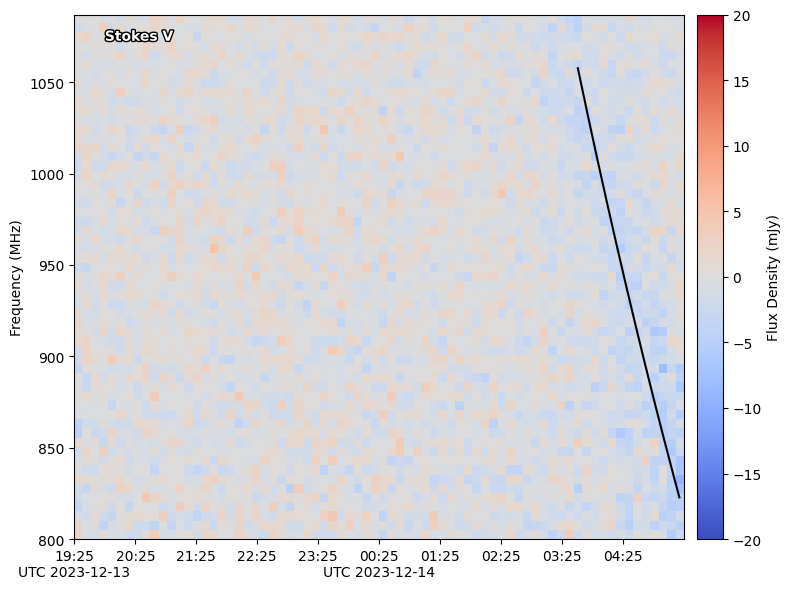

In [211]:
plot_ds(ds, stokes='V')
plt.plot(t_plot, nu_plot, c = 'black')

So in theory now we want to deal with our v_over_H value to determine what the physical CME looks like.

## ECMI

For ECMI, we know $\nu \propto B$, and $B(r) \propto r^{-\ell+2}$, where $\ell = 1$ corresponds to a dipolar field, and $\ell > 1$ corresponds to a higher order field, so we want to fit to a power law.

In [212]:
def power_law(t, A, t0, n):
    return A * (t - t0)**(-n)

In [213]:
A_guess = np.max(nu)
t0_guess = np.min(t) - 0.1*(np.max(t)-np.min(t))
n_guess = 3.0      # dipole-like starting point

p0 = [A_guess, t0_guess, n_guess]

In [214]:
popt, pcov = curve_fit(power_law, t, nu, p0=p0, maxfev=10000)
A_fit, t0_fit, n_fit = popt

In [215]:
perr = np.sqrt(np.diag(pcov))

A_err, t0_err, n_err = perr

print(f"A  = {A_fit:.3f} ± {A_err:.3f}")
print(f"t0 = {t0_fit:.3f} ± {t0_err:.3f}")
print(f"n  = {n_fit:.3f} ± {n_err:.3f}")

A  = 29630.837 ± 366985.018
t0 = -0.946 ± 24.873
n  = 1.501 ± 3.758


In [216]:
nu_fit = power_law(t_plot, *popt)

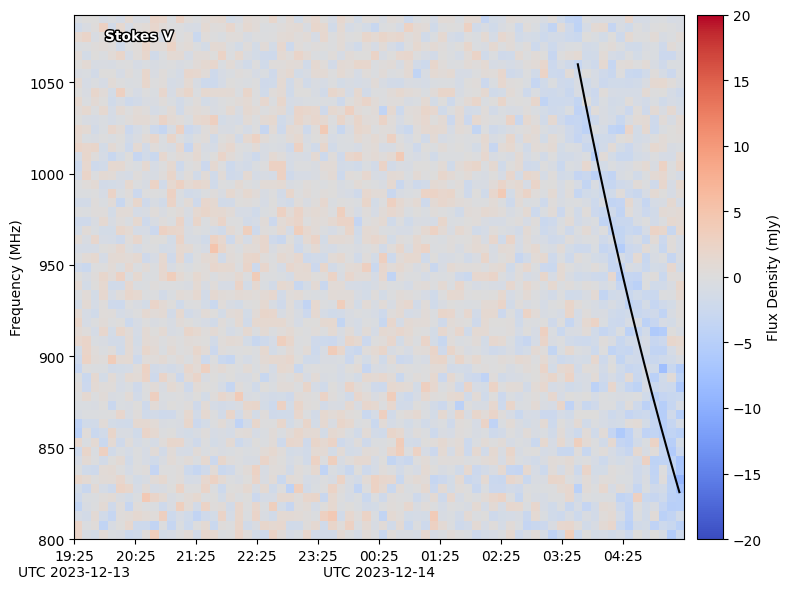

In [217]:
plot_ds(ds, stokes='V')
plt.plot(t_plot, nu_fit, c = 'black')

So it is very difficult to get an estimate on the multipole number from this fit (n spans basically every number we would be interested in).

Next, I want to check how much our frequency binning affects our results by repeating this analysis for different favg values.

# Frequency binning

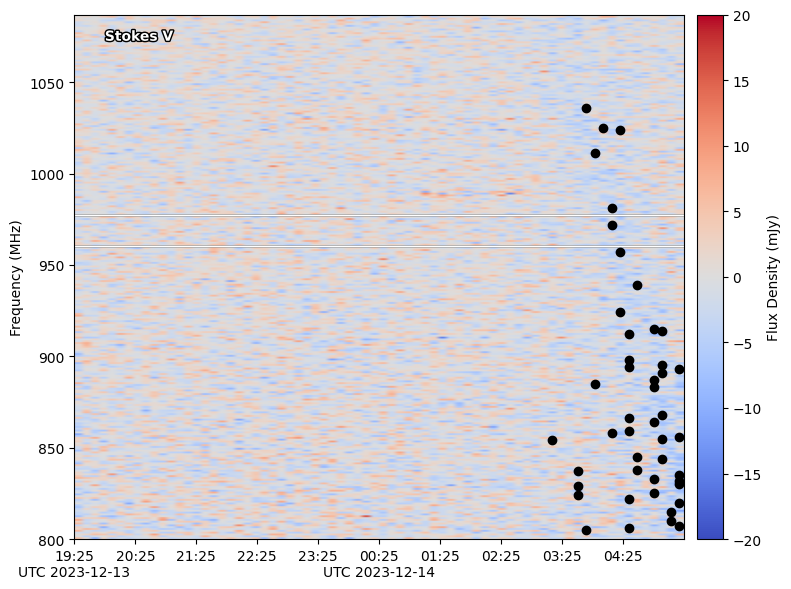

favg: 1, v/H: 0.07850067085250269 +/- 0.03728185057430084
favg: 1, n: 8.565515758502697 +/- 3051.4103447791767


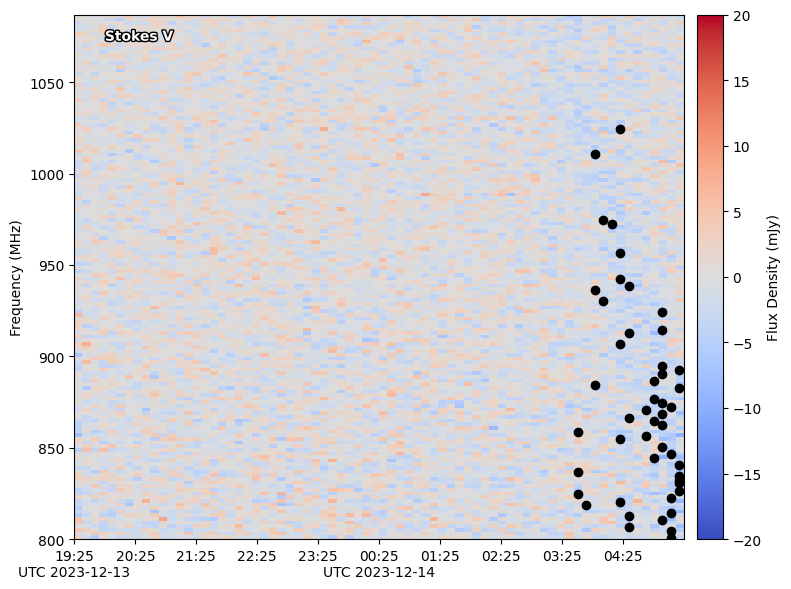

favg: 2, v/H: 0.08129368155864886 +/- 0.03263106103494091
favg: 2, n: 7.787088057157306 +/- 2653.0660710209113


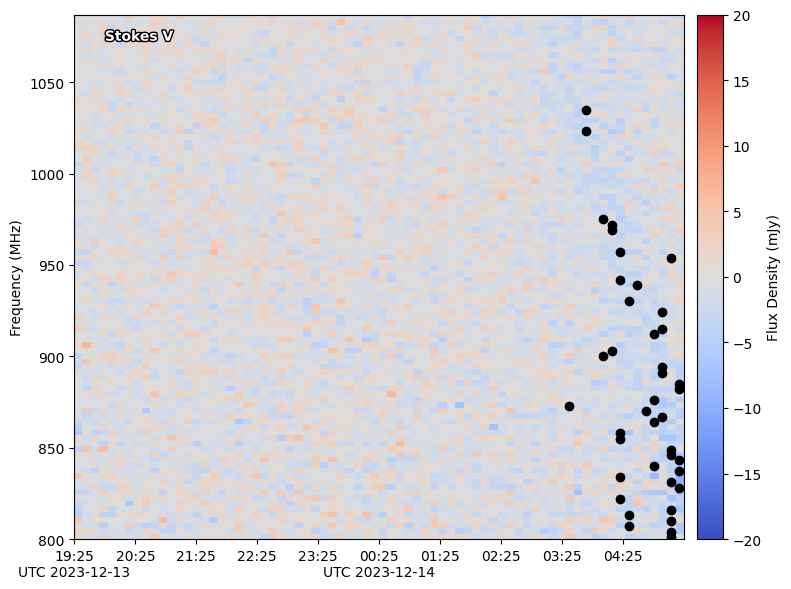

favg: 3, v/H: 0.1423203165882496 +/- 0.03803600757621939
favg: 3, n: 0.46220693833887777 +/- 3.001586659994198


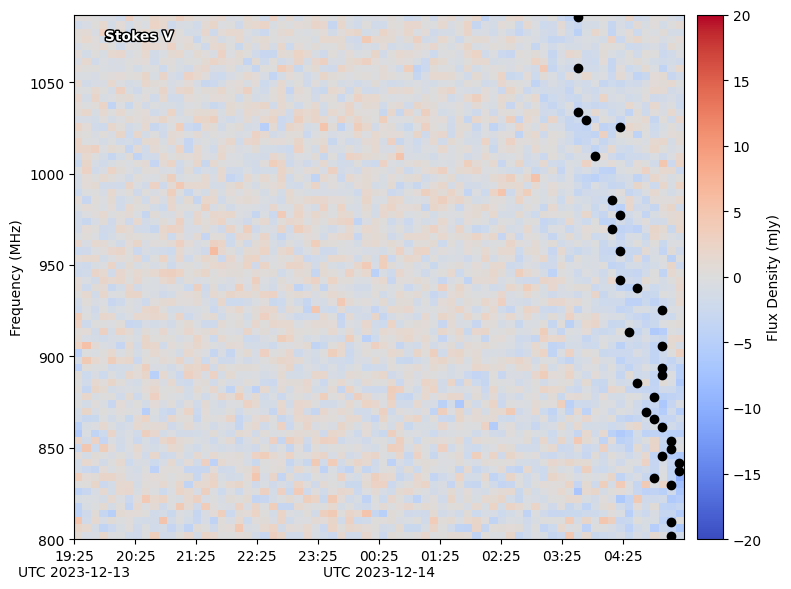

favg: 4, v/H: 0.2951655291733538 +/- 0.02170118599741807
favg: 4, n: 11.529437839722783 +/- 286.46761780057744


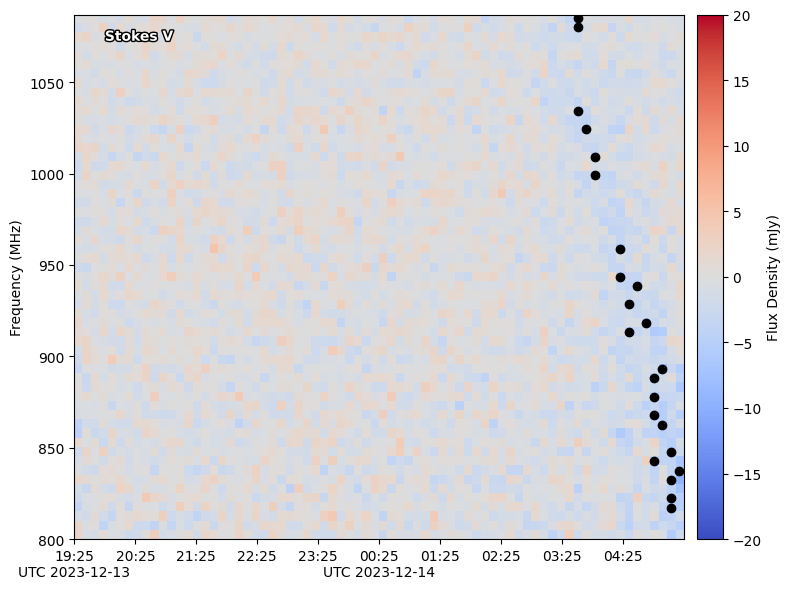

favg: 5, v/H: 0.30143325248348674 +/- 0.01627072444992832
favg: 5, n: 1.5005524649857835 +/- 3.7575409448763684


In [218]:
# To change the filtering
f_vals = [1,2,3,4,5]

for f in f_vals:
    # Create our DS
    ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=f)

    # Create our noise map
    noise = np.nanstd(np.real(ds.data['V'][:30]))
    snr_map = np.real(ds.data['V']) / noise
    mask = snr_map < -3

    # Extract our time/freq grid
    T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
    t_vals = T[mask]
    f_vals = F[mask]

    # Add an extra criteria, burst only occurs at the end of the observation
    t_mask = t_vals > 7.5
    t_vals = t_vals[t_mask]
    f_vals = f_vals[t_mask]

    # Order our arrays so that curvefit likes us
    order = np.argsort(t_vals)
    t_fit = t_vals[order]
    nu_fit = f_vals[order]

    # List of first points
    nu_first = []
    t_first = []
    for freq in np.unique(nu_fit):
        freq_mask = nu_fit == freq
        times = t_fit[freq_mask]
        nu_first.append(freq)
        t_first.append(times[0])
    
    t_first = np.array(t_first)
    nu_first = np.array(nu_first)

    # Sigma clip
    nu, t = nu_first, t_first
    for i in range(0,10): # to ensure we dont go on forever
        nu, t, mask_sum = sigma_clip(nu, t, sig=2, plot=False)
        if mask_sum == 0:
            break

    # Plot our fits
    plot_ds(ds, stokes='V')
    plt.scatter(t, nu, c = 'black')
    plt.show()
    plt.close()

    # Assume a plasma model
    p0 = [np.max(nu),1,np.min(t)]
    popt, pcov = curve_fit(exp_model, t, nu, p0=p0, maxfev=1000000)
    nu0_fit, v_over_H_fit, t0_fit = popt
    nu0_err, v_over_H_err, t0_err = np.sqrt(np.diag(pcov))
    print(f'favg: {f}, v/H: {v_over_H_fit} +/- {v_over_H_err}')

    # Assume an ECMI model
    A_guess = np.max(nu)
    t0_guess = np.min(t) - 0.1*(np.max(t)-np.min(t))
    n_guess = 3.0      # dipole-like starting point
    p0 = [A_guess, t0_guess, n_guess]
    popt, pcov = curve_fit(power_law, t, nu, p0=p0, maxfev=1000000)
    A_fit, t0_fit, n_fit = popt
    A_err, t0_err, n_err = np.sqrt(np.diag(pcov))
    print(f'favg: {f}, n: {n_fit} +/- {n_err}')

# Improvements

Instead of removing many data points iteratively, what if we only removed a few points and then fit to the centroid instead? We already have huge uncertainties in our measurements due to the nature of this low SNR burst, so let's try and minimise our interference with the data. Additionally, the physically motivated fits did not appear to fit the data well, so what if we just assume we are in a regime where the effect is linear/quadratic? (i.e. Joe's paper).

Start with a new minimal data reduction method, then fit a linear/quadratic fit across a range of averaging factors. We know from earlier that we only have the burst from ~8hrs onwards

(<Figure size 800x600 with 2 Axes>, <Axes: ylabel='Frequency (MHz)'>)

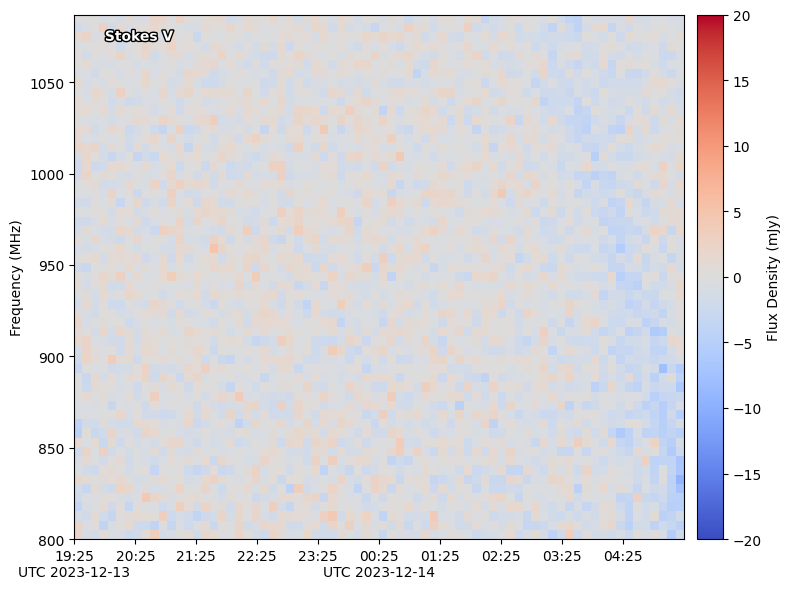

In [219]:
tavg=50
favg=5
ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=favg)
plot_ds(ds, stokes='V')

To find our noise, we can't simply slice on index, since that changes depending on our filtering scale if we change our time filtering, so let's take the first 40% of data and use that, since it appears to be well out of the way of the burst itself.

In [220]:
noise_length = int((4/10) * len(ds.time))

In [221]:
noise = np.nanstd(np.real(ds.data['V'][:noise_length]))
snr_map = np.real(ds.data['V']) / noise
mask = snr_map < -3 # One sided

In [222]:
T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
t_vals = T[mask]
f_vals = F[mask]

In [223]:
t_mask = t_vals > 7.5
t_vals = t_vals[t_mask]
f_vals = f_vals[t_mask]

In [224]:
# Order our arrays so that curvefit likes us
order = np.argsort(t_vals)
t_fit = t_vals[order]
nu_fit = f_vals[order]

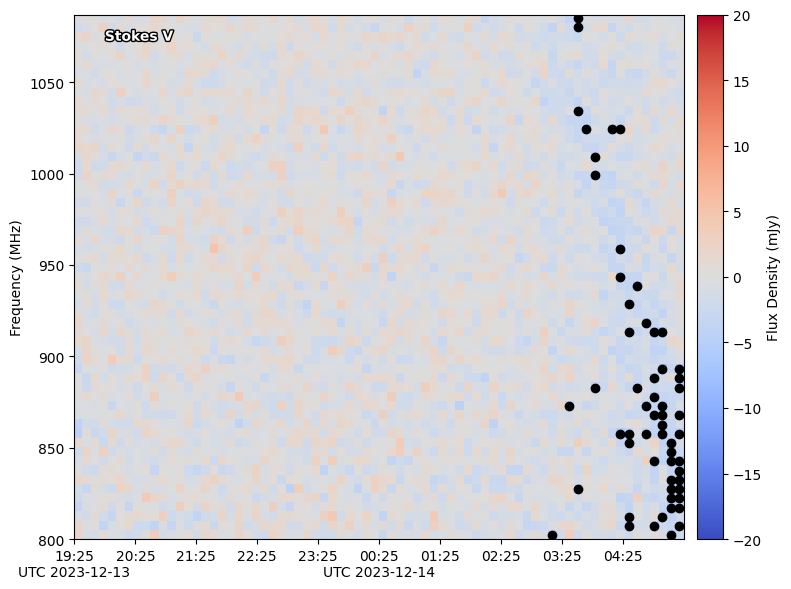

In [225]:
plot_ds(ds, stokes='V')
plt.scatter(t_fit, nu_fit, c = 'black')
plt.show()
plt.close()

We could justifiably remove a few more of these, but I want to see if it still works without manual intervention.

In [80]:
def linear(t, a, b):
    return a * t + b

def quadratic(t, a, b):
    return a * t**2 + b

In [227]:
# Linear model
popt_l, pcov_l = curve_fit(linear, t_fit, nu_fit, maxfev=10000000)
lin_slope, lin_intercept = popt_l
lin_slope_err, lin_intercept_err = np.sqrt(np.diag(pcov_l))

# Quadratic model
popt_q, pcov_q = curve_fit(quadratic, t_fit, nu_fit, maxfev=10000000)
quad_slope, quad_intercept = popt_q
quad_slope_err, quad_intercept_err = np.sqrt(np.diag(pcov_q))

In [228]:
t_plot = np.linspace(t_fit.min(), t_fit.max(), 500) # Interpolate over a smooth grid
nu_linear = linear(t_plot, *popt_l)
nu_quad = quadratic(t_plot, *popt_q)

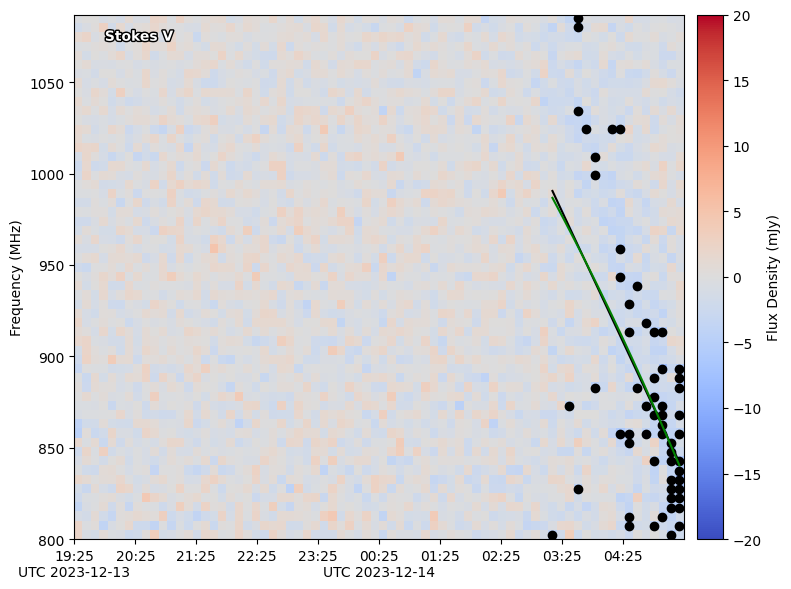

In [229]:
plot_ds(ds, stokes='V')
plt.scatter(t_fit, nu_fit, c = 'black')
plt.plot(t_plot, nu_linear, c = 'black')
plt.plot(t_plot, nu_quad, c = 'green')

In [230]:
print(np.abs(quad_slope_err / quad_slope))
print(np.abs(lin_slope_err / lin_slope))

0.18784645344335665
0.19016818393048435


It doesn't look like this worked very well... I want to try removing those data points at the bottom, as well as trying to repeat over a larger sample of tavg, favg.

In [231]:
t_fit

array([7.84171849, 8.11935719, 8.2581708 , 8.2581708 , 8.2581708 ,
       8.2581708 , 8.3969844 , 8.53579801, 8.53579801, 8.53579801,
       8.81343671, 8.95225032, 8.95225032, 8.95225032, 8.95225032,
       9.09106393, 9.09106393, 9.09106393, 9.09106393, 9.09106393,
       9.09106393, 9.22987754, 9.22987754, 9.36870032, 9.36870032,
       9.36870032, 9.50751623, 9.50751623, 9.50751623, 9.50751623,
       9.50751623, 9.50751623, 9.64632984, 9.64632984, 9.64632984,
       9.64632984, 9.64632984, 9.64632984, 9.64632984, 9.78514345,
       9.78514345, 9.78514345, 9.78514345, 9.78514345, 9.78514345,
       9.78514345, 9.78514345, 9.92395706, 9.92395706, 9.92395706,
       9.92395706, 9.92395706, 9.92395706, 9.92395706, 9.92395706,
       9.92395706, 9.92395706, 9.92395706, 9.92395706])

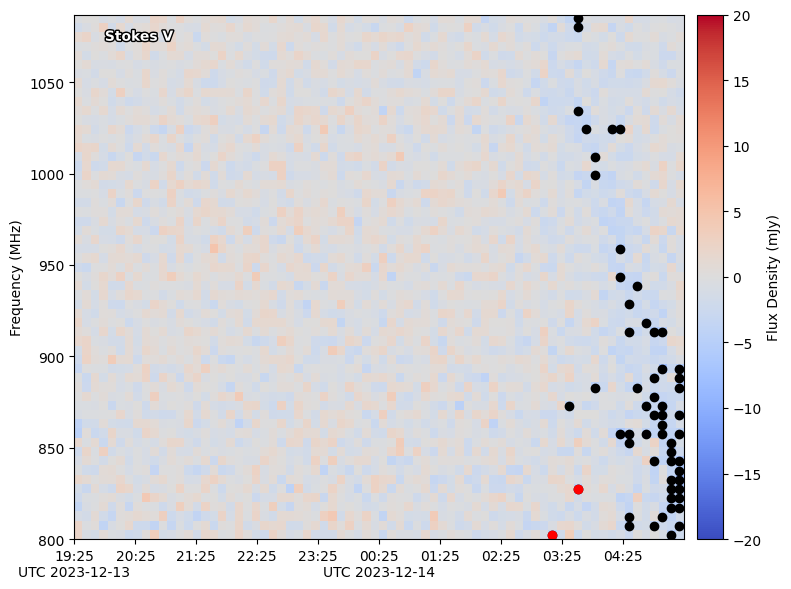

In [232]:
plot_ds(ds, stokes='V')
plt.scatter(t_fit, nu_fit, c = 'black')
plt.scatter(t_fit[0], nu_fit[0], c = 'red')
plt.scatter(t_fit[2], nu_fit[2], c = 'red')

In [233]:
t_fit = np.delete(t_fit, [0,2])
nu_fit = np.delete(nu_fit, [0,2])

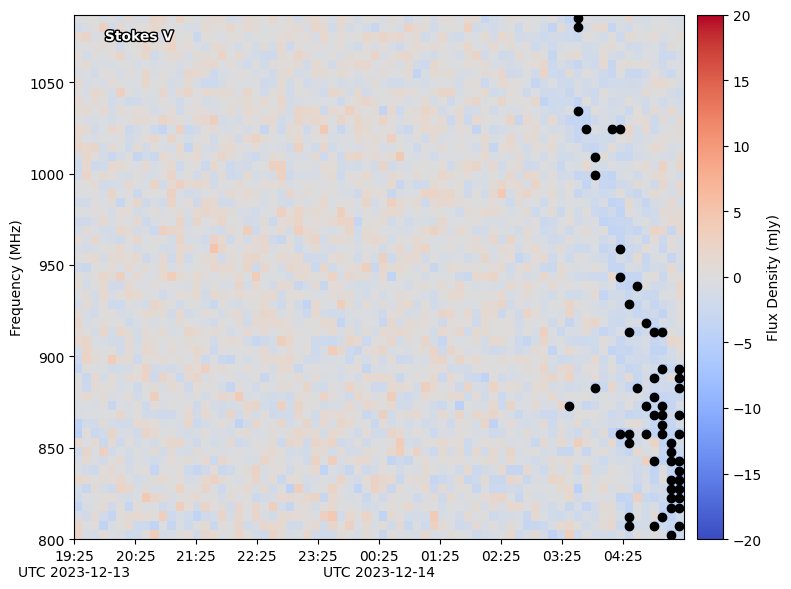

In [234]:
plot_ds(ds, stokes='V')
plt.scatter(t_fit, nu_fit, c = 'black')

In [235]:
# Linear model
popt_l, pcov_l = curve_fit(linear, t_fit, nu_fit, maxfev=10000000)
lin_slope, lin_intercept = popt_l
lin_slope_err, lin_intercept_err = np.sqrt(np.diag(pcov_l))

# Quadratic model
popt_q, pcov_q = curve_fit(quadratic, t_fit, nu_fit, maxfev=10000000)
quad_slope, quad_intercept = popt_q
quad_slope_err, quad_intercept_err = np.sqrt(np.diag(pcov_q))

In [236]:
t_plot = np.linspace(t_fit.min(), t_fit.max(), 500) # Interpolate over a smooth grid
nu_linear = linear(t_plot, *popt_l)
nu_quad = quadratic(t_plot, *popt_q)

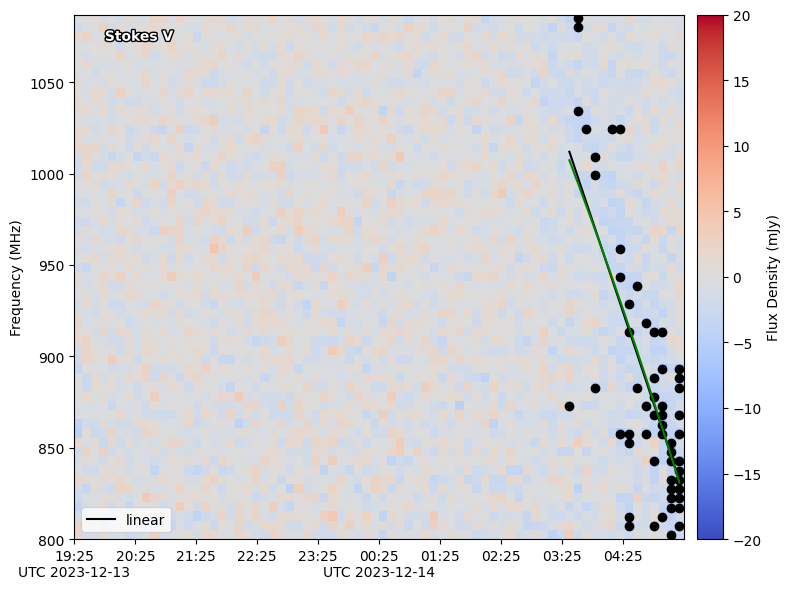

In [237]:
plot_ds(ds, stokes='V')
plt.scatter(t_fit, nu_fit, c = 'black')
plt.plot(t_plot, nu_linear, c = 'black', label = 'linear')
plt.plot(t_plot, nu_quad, c = 'green')
plt.legend(loc = 'lower left')

This does appear to work quite well, but let's also try looping over a range of tavg, favg since they all might need manual data pruning.

In [238]:
f_averages = [1,2,3,5,10,15]
t_averages = [1,5,10,25,50,75,100]

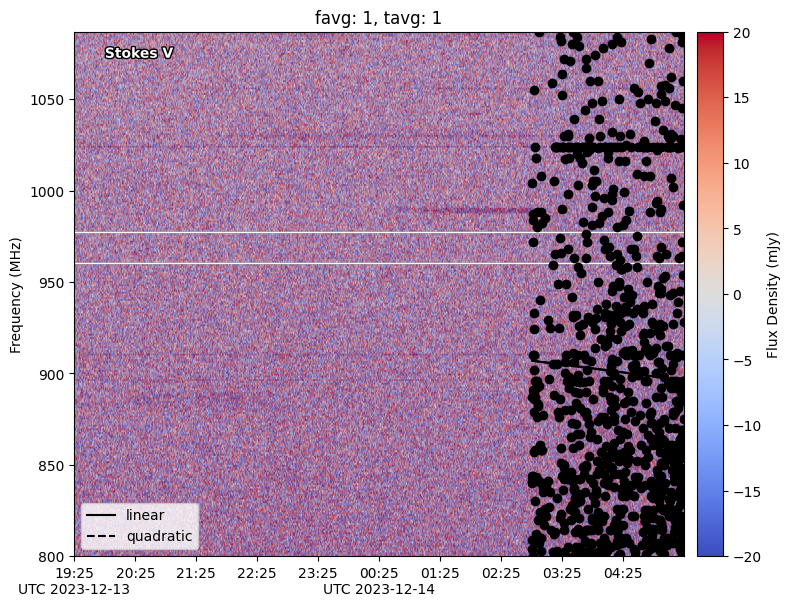

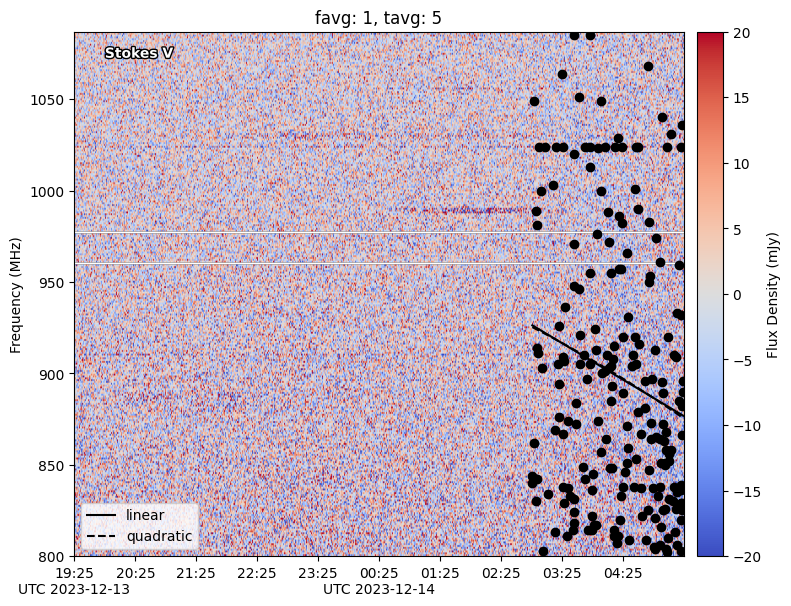

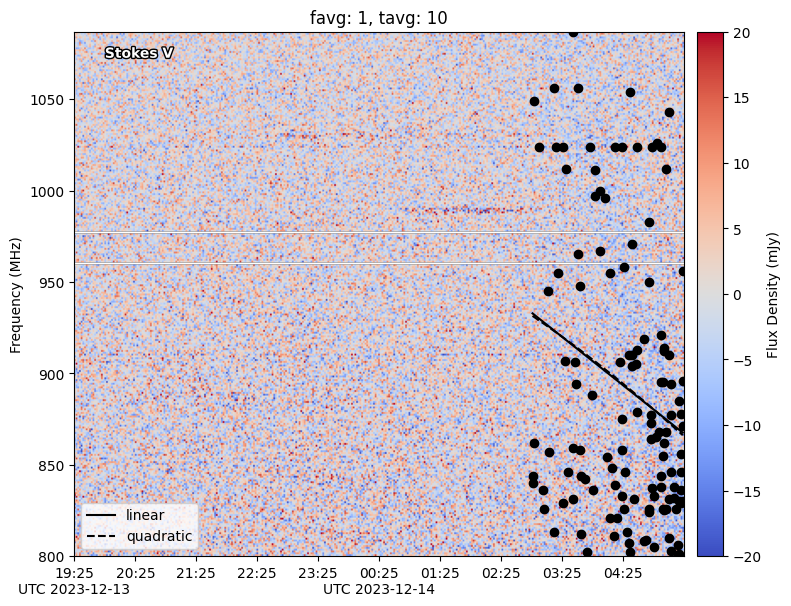

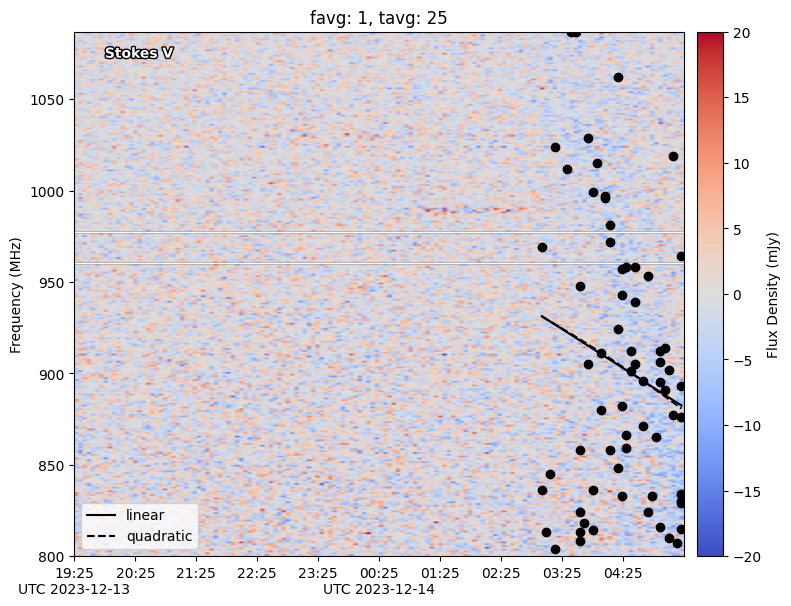

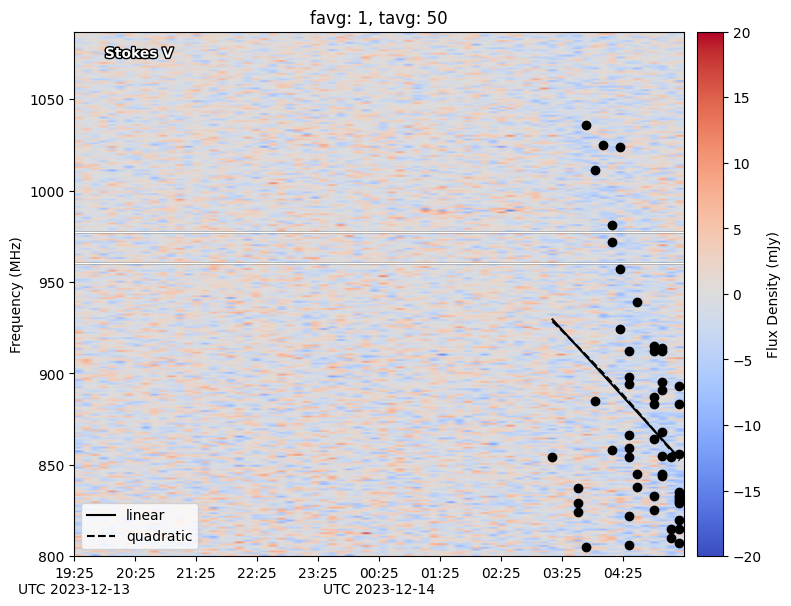

...

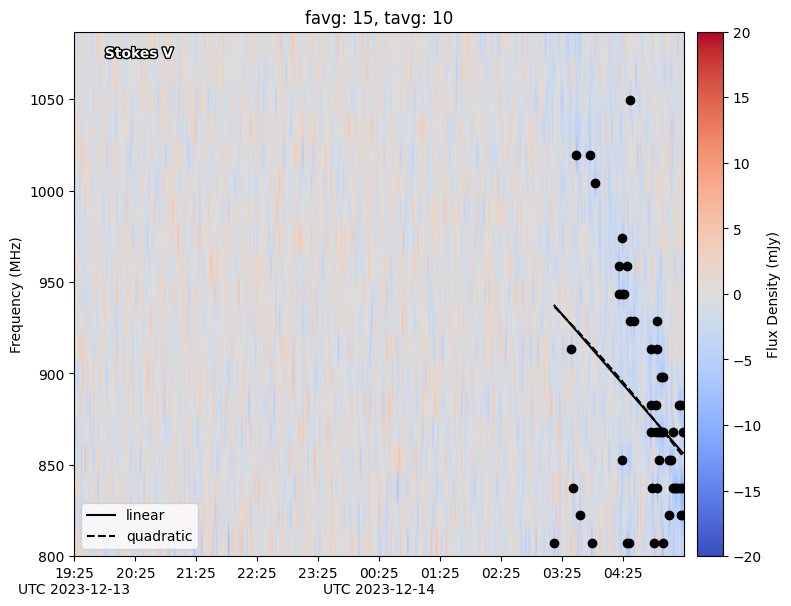

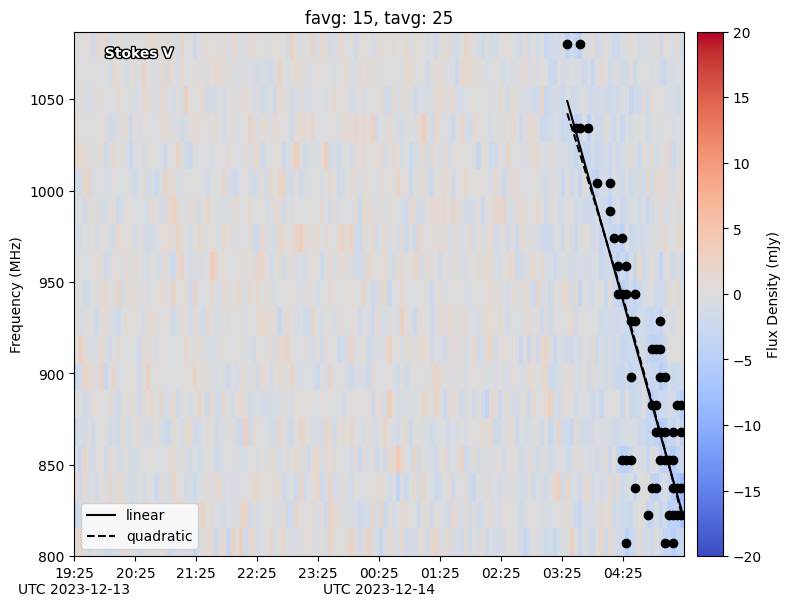

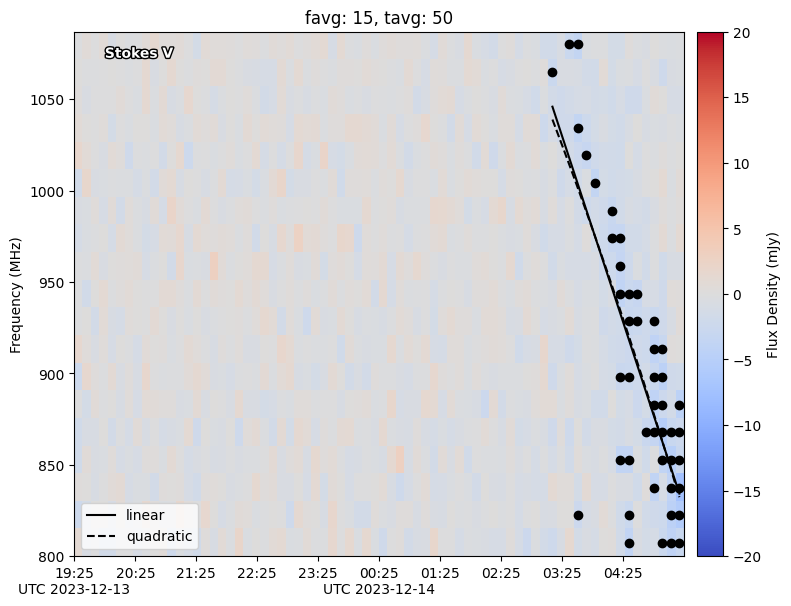

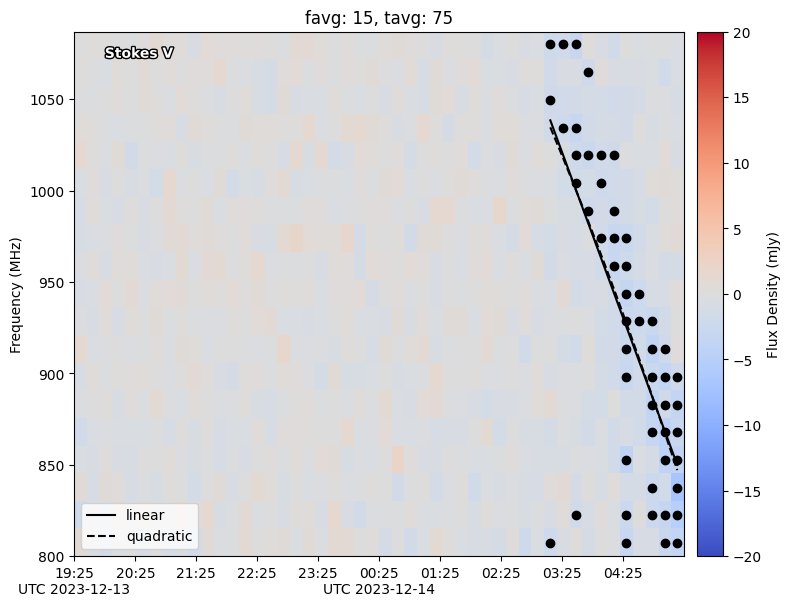

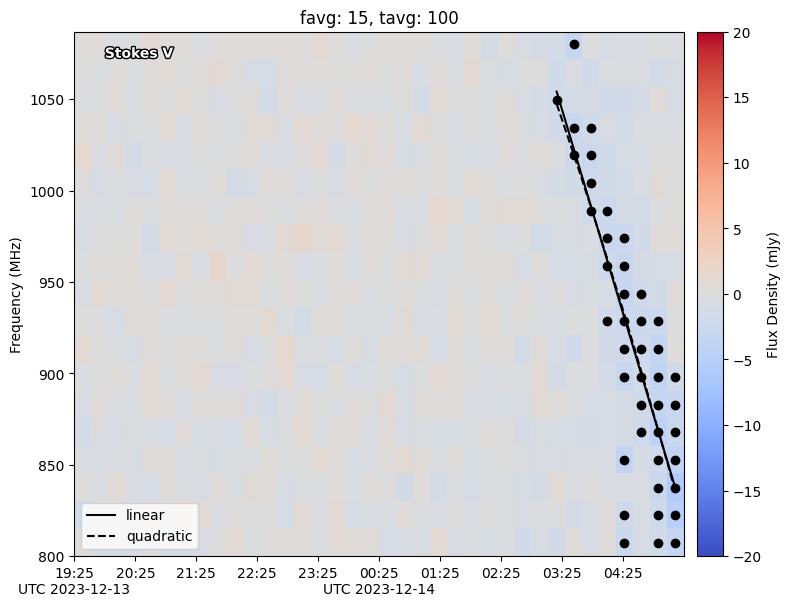

In [239]:
slopes_l, slopes_l_err, slopes_q, slopes_q_err = [], [], [], []

for f in f_averages:
    for t in t_averages:

        # Make the DS
        ds = DynamicSpectrum(ds_path=matches[0],tavg=t, favg=f)
        
        # SNR Mask
        noise_length = int((4/10) * len(ds.time))
        noise = np.nanstd(np.real(ds.data['V'][:noise_length]))
        snr_map = np.real(ds.data['V']) / noise
        mask = snr_map < -3 # One sided

        # Time mask & data formatting
        T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
        t_vals = T[mask]
        f_vals = F[mask]
        
        t_mask = t_vals > 7.5
        t_vals = t_vals[t_mask]
        f_vals = f_vals[t_mask]

        # Order our arrays so that curvefit likes us
        order = np.argsort(t_vals)
        t_fit = t_vals[order]
        nu_fit = f_vals[order]

        # Linear model
        popt_l, pcov_l = curve_fit(linear, t_fit, nu_fit, maxfev=10000000)
        lin_slope, lin_intercept = popt_l
        lin_slope_err, lin_intercept_err = np.sqrt(np.diag(pcov_l))
        
        # Quadratic model
        popt_q, pcov_q = curve_fit(quadratic, t_fit, nu_fit, maxfev=10000000)
        quad_slope, quad_intercept = popt_q
        quad_slope_err, quad_intercept_err = np.sqrt(np.diag(pcov_q))

        # Save our results
        slopes_l.append(lin_slope)
        slopes_l_err.append(lin_slope_err)
        slopes_q.append(quad_slope)
        slopes_q_err.append(quad_slope_err)

        # Calculate our models
        t_plot = np.linspace(t_fit.min(), t_fit.max(), 500) # Interpolate over a smooth grid
        nu_linear = linear(t_plot, *popt_l)
        nu_quad = quadratic(t_plot, *popt_q)

        # Plot our models v data
        plot_ds(ds, stokes='V')
        plt.scatter(t_fit, nu_fit, c = 'black')
        plt.plot(t_plot, nu_linear, c = 'black', label = 'linear')
        plt.plot(t_plot, nu_quad, c = 'black', ls = '--', label = 'quadratic')
        plt.legend(loc = 'lower left')
        plt.title(f'favg: {f}, tavg: {t}')
        plt.show()
        plt.close()

The gist I get from this is that we need high t averages to get a clean relation out. We can also see that our quadratic seems to quite closely follow our linear in almost all cases (i.e. the linear model should be better I think?).

To confirm, let's just repeat with only high t and f averaging and see if we get somewhat agreeable results.

In [78]:
f_averages = [5,10,15,20,25]
t_averages = [50, 75, 100, 125, 150]

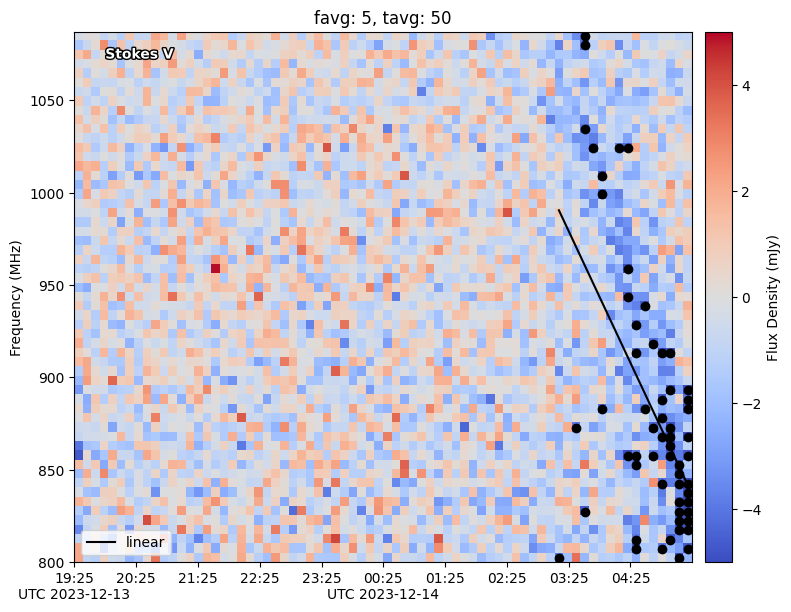

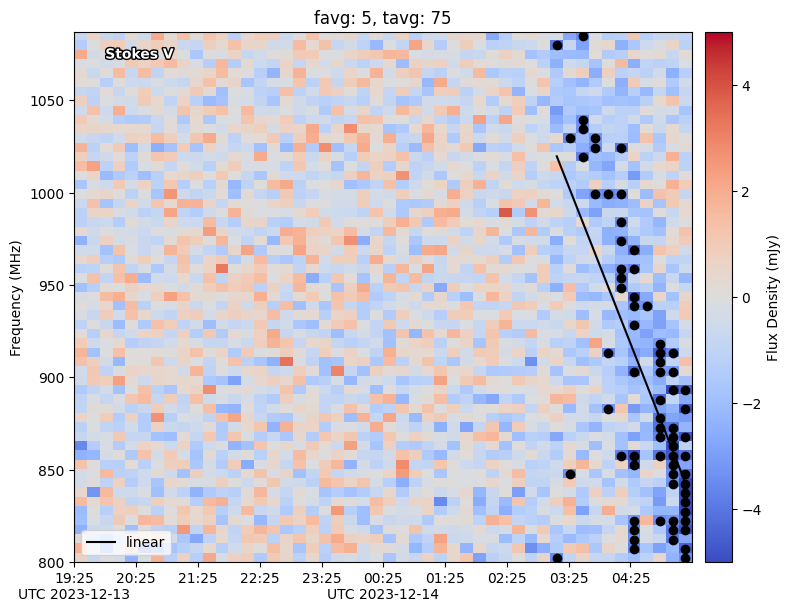

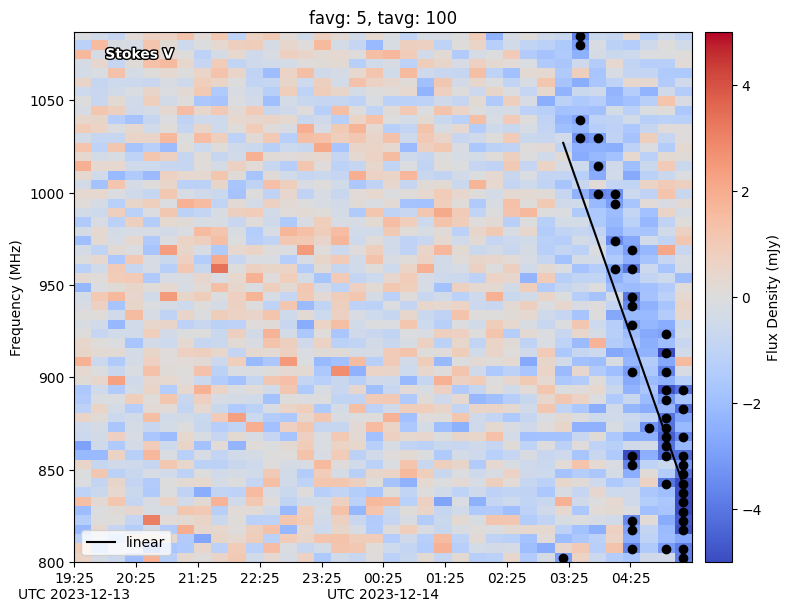

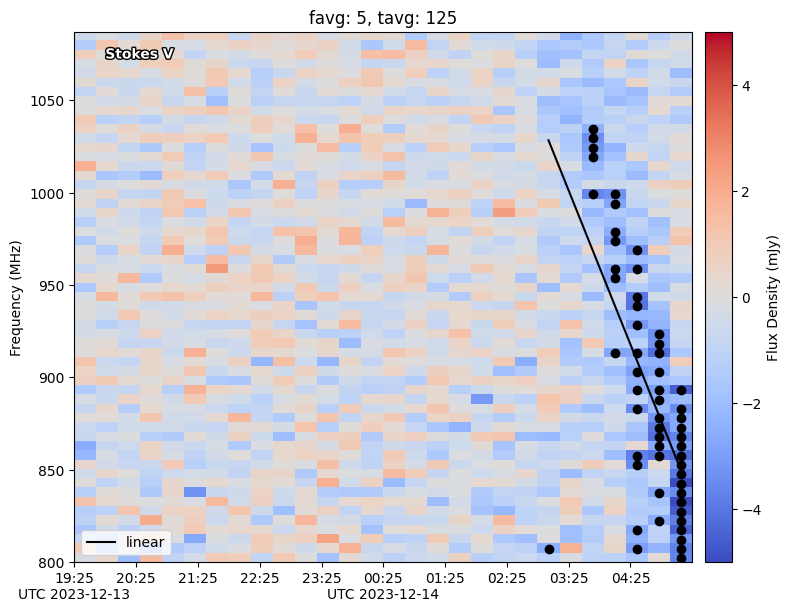

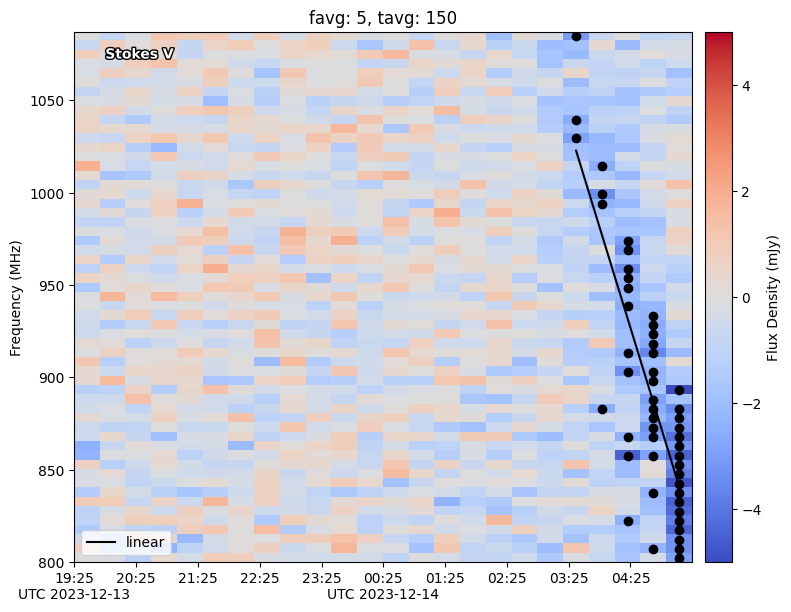

...

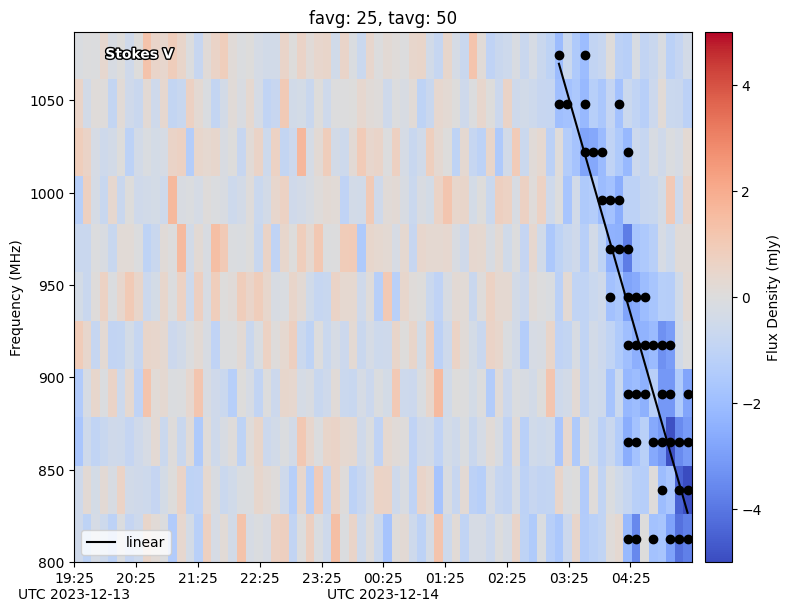

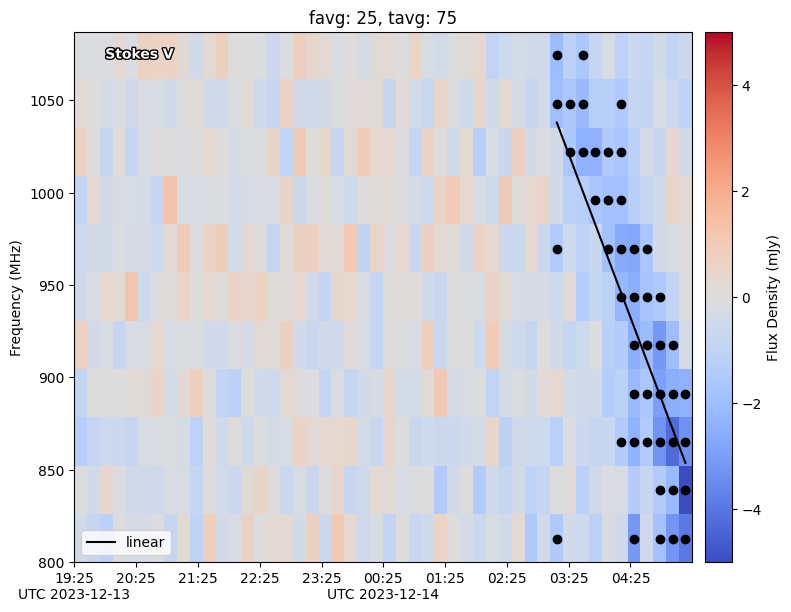

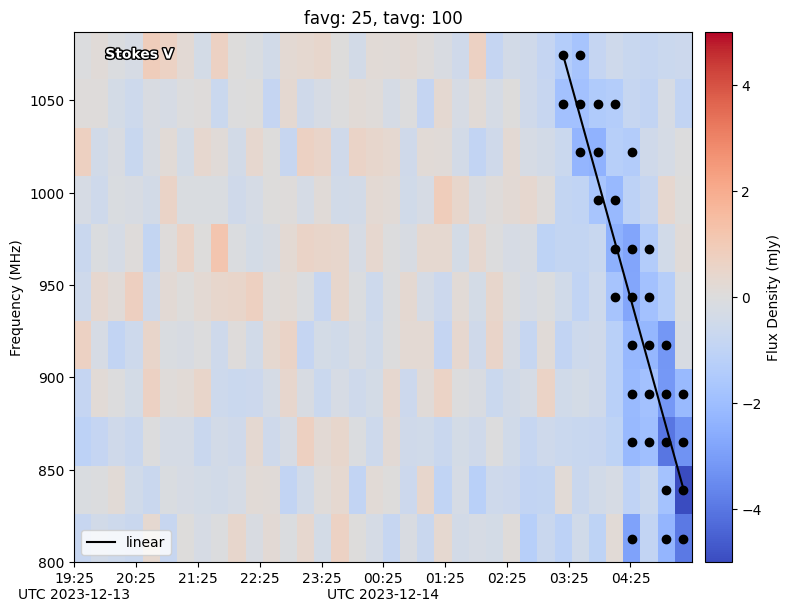

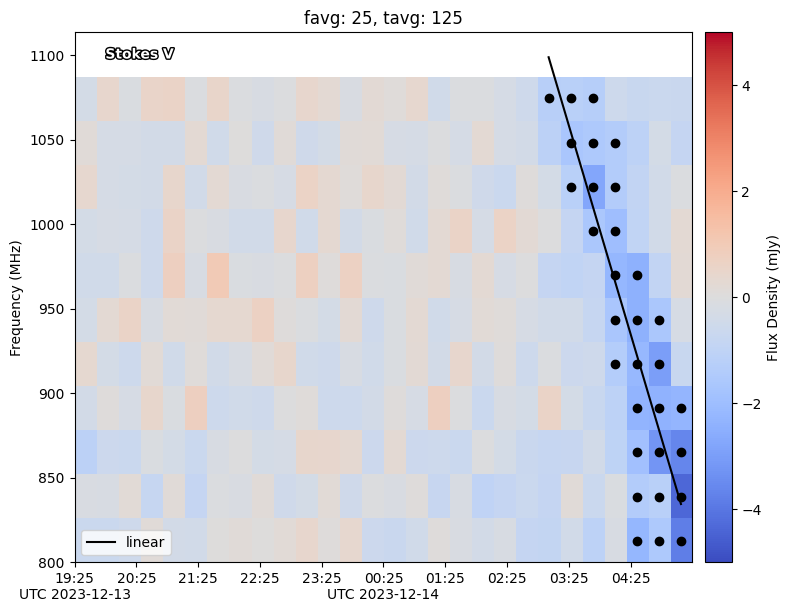

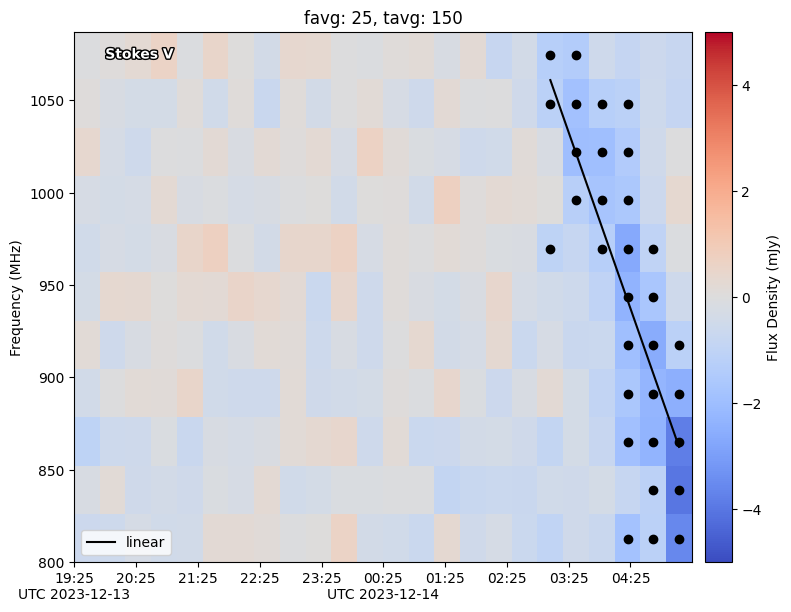

In [81]:
slopes_l, slopes_l_err, slopes_q, slopes_q_err = [], [], [], []

for f in f_averages:
    for t in t_averages:

        # Make the DS
        ds = DynamicSpectrum(ds_path=matches[0],tavg=t, favg=f)
        
        # SNR Mask
        noise_length = int((4/10) * len(ds.time))
        noise = np.nanstd(np.real(ds.data['V'][:noise_length]))
        snr_map = np.real(ds.data['V']) / noise
        mask = snr_map < -3 # One sided

        # Time mask & data formatting
        T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
        t_vals = T[mask]
        f_vals = F[mask]
        
        t_mask = t_vals > 7.5
        t_vals = t_vals[t_mask]
        f_vals = f_vals[t_mask]

        # Order our arrays so that curvefit likes us
        order = np.argsort(t_vals)
        t_fit = t_vals[order]
        nu_fit = f_vals[order]

        # Linear model
        popt_l, pcov_l = curve_fit(linear, t_fit, nu_fit, maxfev=10000000) # remove this maxfev thing
        lin_slope, lin_intercept = popt_l
        lin_slope_err, lin_intercept_err = np.sqrt(np.diag(pcov_l))
        
        # Quadratic model
        popt_q, pcov_q = curve_fit(quadratic, t_fit, nu_fit, maxfev=10000000)
        quad_slope, quad_intercept = popt_q
        quad_slope_err, quad_intercept_err = np.sqrt(np.diag(pcov_q))

        # Save our results
        slopes_l.append(lin_slope)
        slopes_l_err.append(lin_slope_err)
        slopes_q.append(quad_slope)
        slopes_q_err.append(quad_slope_err)

        # Calculate our models
        t_plot = np.linspace(t_fit.min(), t_fit.max(), 500) # Interpolate over a smooth grid
        nu_linear = linear(t_plot, *popt_l)
        nu_quad = quadratic(t_plot, *popt_q)

        # Plot our models v data
        plot_ds(ds, stokes='V', cmax=5)
        plt.scatter(t_fit, nu_fit, c = 'black')
        plt.plot(t_plot, nu_linear, c = 'black', label = 'linear')
        # plt.plot(t_plot, nu_quad, c = 'black', ls = '--', label = 'quadratic')
        plt.legend(loc = 'lower left')
        plt.title(f'favg: {f}, tavg: {t}')
        plt.show()
        plt.close()

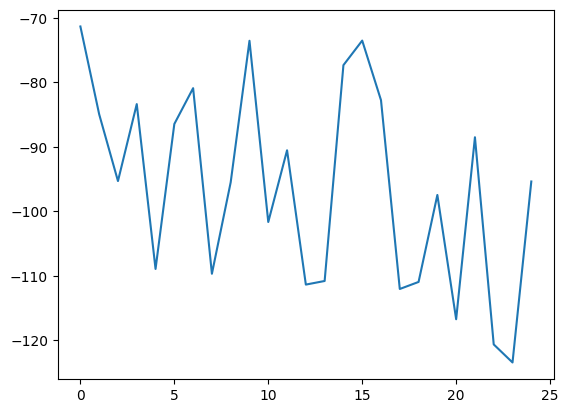

In [242]:
plt.plot(slopes_l)

So we are assuming that the slope is ~ -100 MHz/Hr

# Frequency cutting

Since we have so many points at the lower end of our DS, it becomes difficult to get a good fit by eye, so what if we cut out the lower frequencies that are causing this issue and check we still get a roughly consistent looking fit.

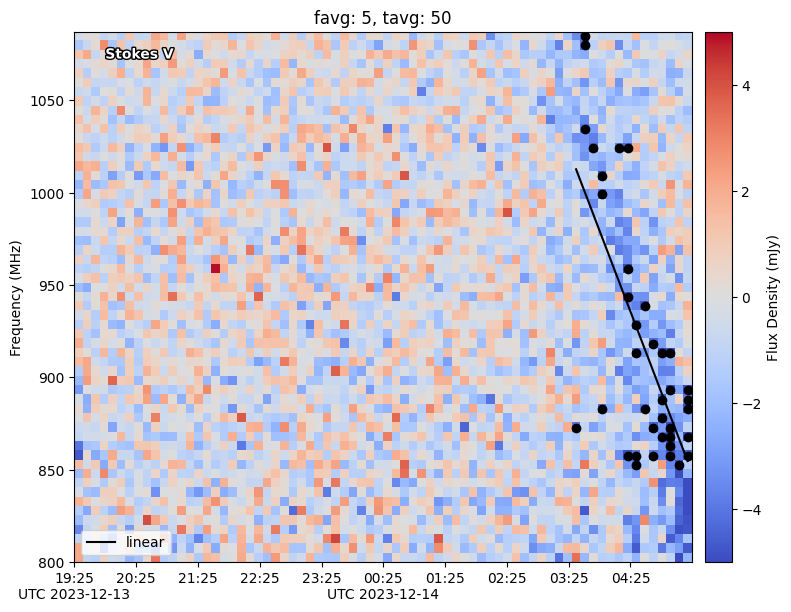

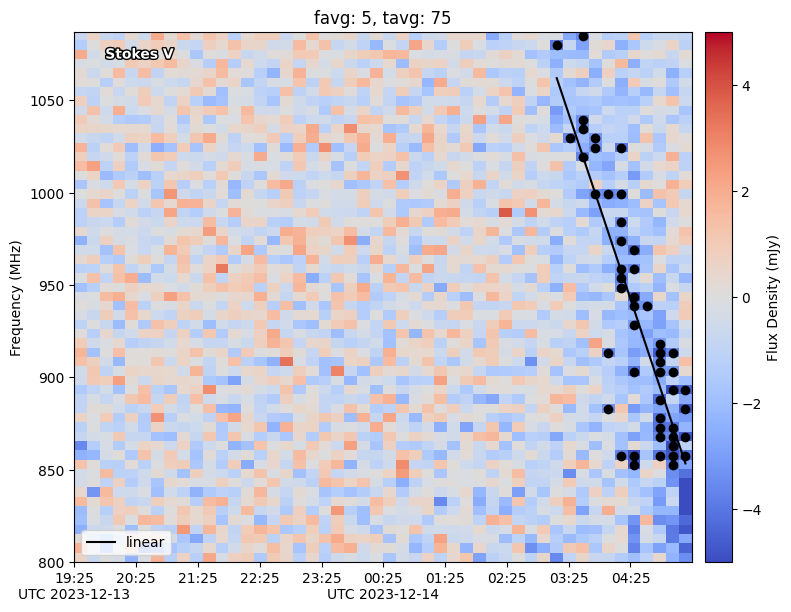

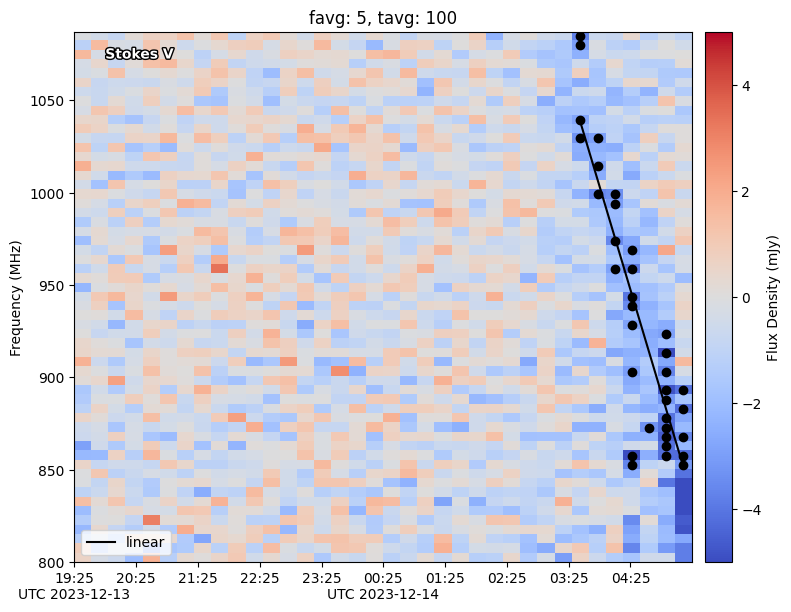

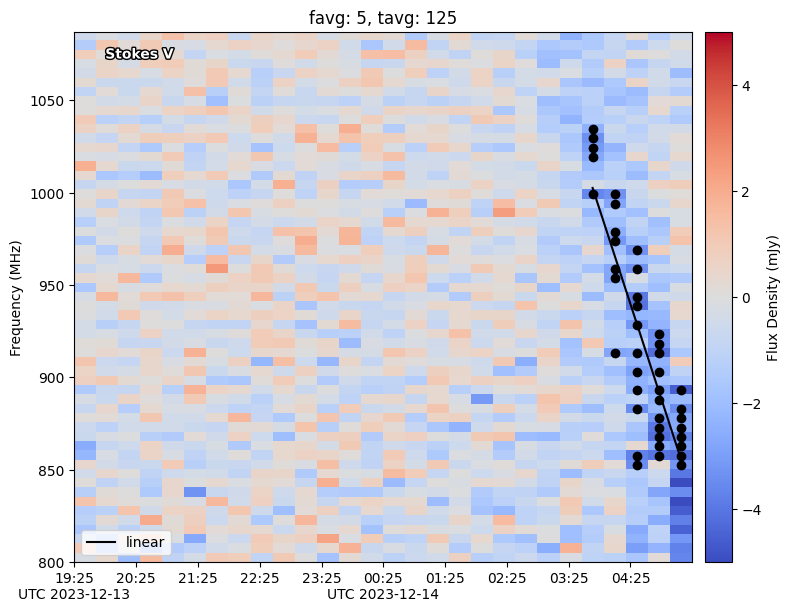

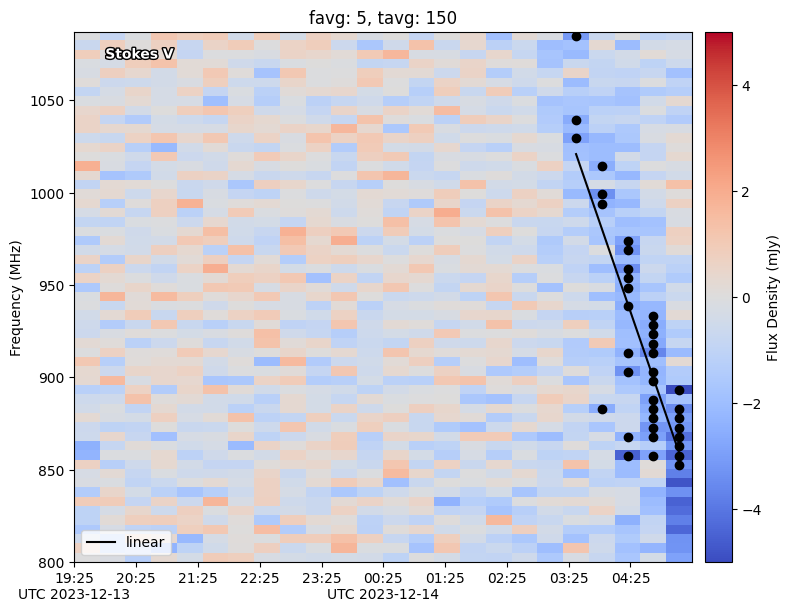

...

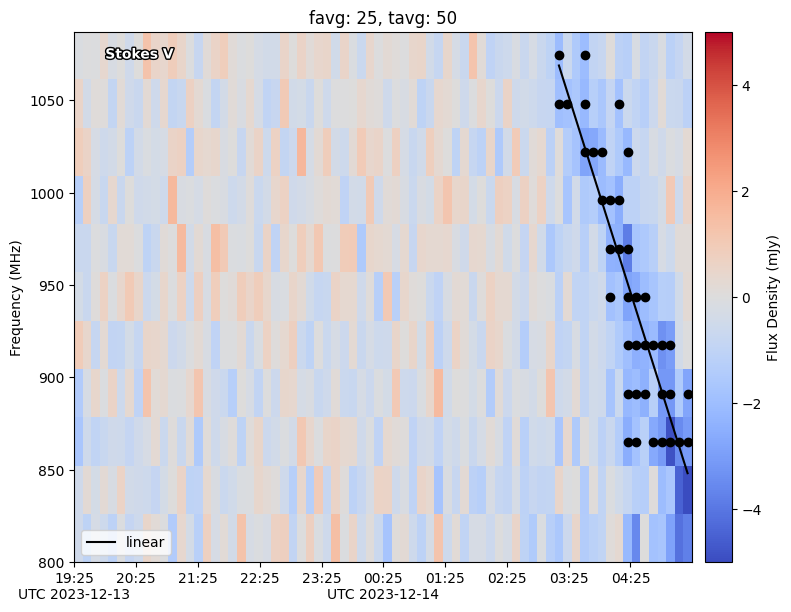

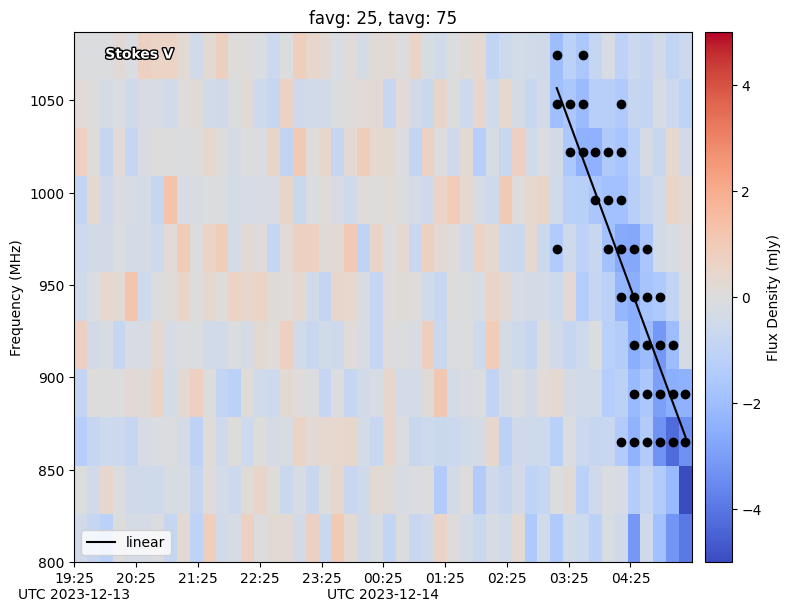

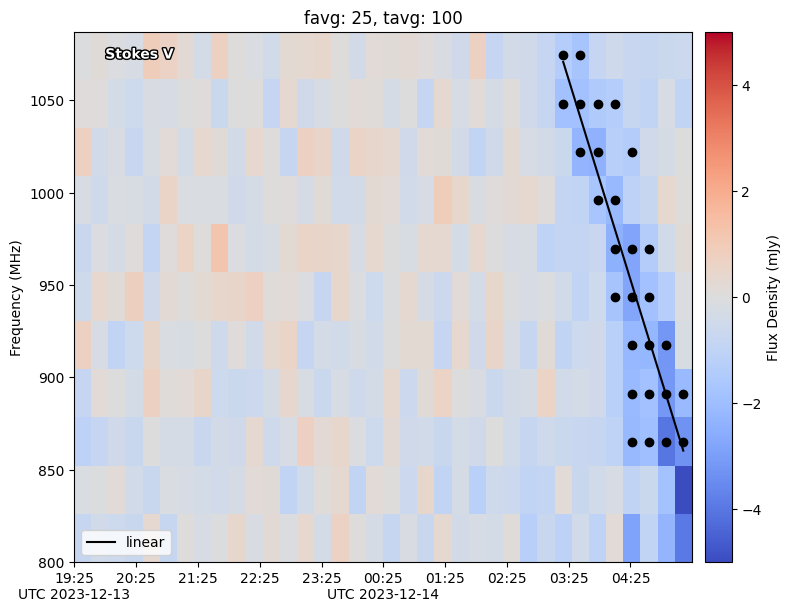

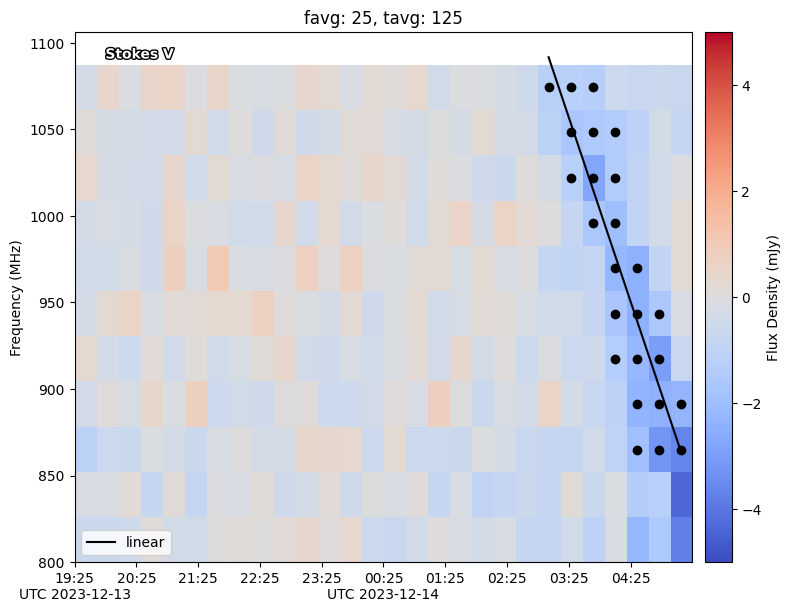

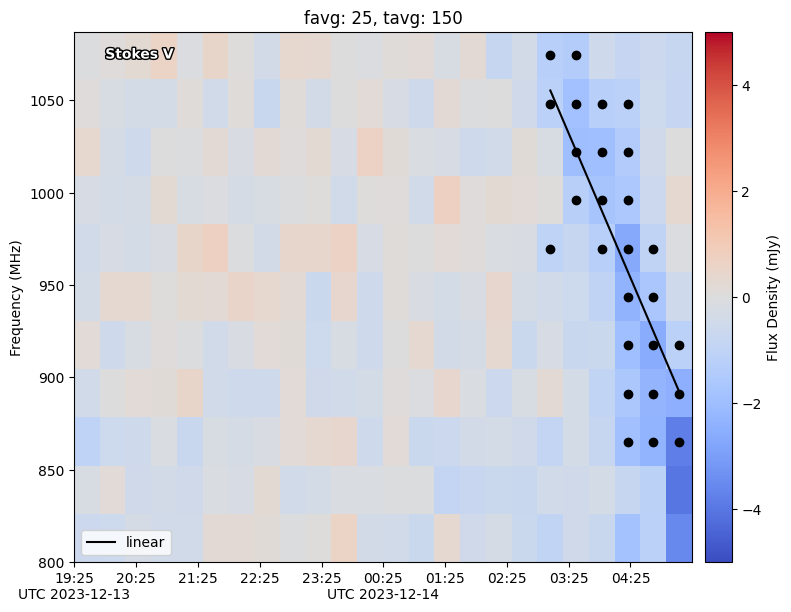

In [82]:
slopes_l, slopes_l_err, slopes_q, slopes_q_err = [], [], [], []

for f in f_averages:
    for t in t_averages:

        # Make the DS
        ds = DynamicSpectrum(ds_path=matches[0],tavg=t, favg=f)
        
        # SNR Mask
        noise_length = int((4/10) * len(ds.time))
        noise = np.nanstd(np.real(ds.data['V'][:noise_length]))
        snr_map = np.real(ds.data['V']) / noise
        mask = snr_map < -3 # One sided

        # Time mask & data formatting
        T, F = np.meshgrid(ds.time, ds.freq, indexing="ij")
        t_vals = T[mask]
        f_vals = F[mask]
        
        t_mask = t_vals > 7.5
        t_vals = t_vals[t_mask]
        f_vals = f_vals[t_mask]

        # Just added this mask in
        f_mask = f_vals > 850
        t_vals = t_vals[f_mask]
        f_vals = f_vals[f_mask]

        # Order our arrays so that curvefit likes us
        order = np.argsort(t_vals)
        t_fit = t_vals[order]
        nu_fit = f_vals[order]

        # Linear model
        popt_l, pcov_l = curve_fit(linear, t_fit, nu_fit)
        lin_slope, lin_intercept = popt_l
        lin_slope_err, lin_intercept_err = np.sqrt(np.diag(pcov_l))
        
        # Quadratic model
        popt_q, pcov_q = curve_fit(quadratic, t_fit, nu_fit)
        quad_slope, quad_intercept = popt_q
        quad_slope_err, quad_intercept_err = np.sqrt(np.diag(pcov_q))

        # Save our results
        slopes_l.append(lin_slope)
        slopes_l_err.append(lin_slope_err)
        slopes_q.append(quad_slope)
        slopes_q_err.append(quad_slope_err)

        # Calculate our models
        t_plot = np.linspace(t_fit.min(), t_fit.max(), 500) # Interpolate over a smooth grid
        nu_linear = linear(t_plot, *popt_l)
        nu_quad = quadratic(t_plot, *popt_q)

        # Plot our models v data
        plot_ds(ds, stokes='V',cmax=5)
        plt.scatter(t_fit, nu_fit, c = 'black')
        plt.plot(t_plot, nu_linear, c = 'black', label = 'linear')
        # plt.plot(t_plot, nu_quad, c = 'black', ls = '--', label = 'quadratic')
        plt.legend(loc = 'lower left')
        plt.title(f'favg: {f}, tavg: {t}')
        plt.show()
        plt.close()

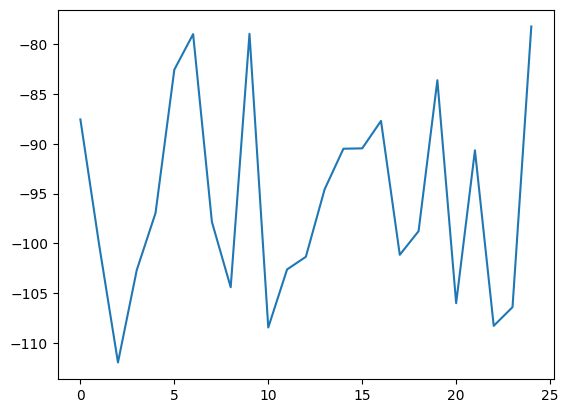

In [244]:
plt.plot(slopes_l)

So even after that cut, we get a fairly consistent slope estimate, centred around -95 MHz/hr like before.

In [245]:
np.mean(slopes_l)

np.float64(-95.62862508835008)

In [246]:
np.std(slopes_l)

np.float64(9.95123571891542)

# DS Plots for thesis

In [175]:
vis_path = Path('../visibility_files/')
ds_files = list(vis_path.rglob('*.ds'))

In [230]:
matches = [p for p in ds_files if "tyc_8927_54101" in str(p)]

In [231]:
matches

[PosixPath('../visibility_files/tyc_8927-1888-1/54101/tyc_8927_54101.ds')]

In [244]:
tavg=30
favg=3
ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=favg)
lc = LightCurve(ds)

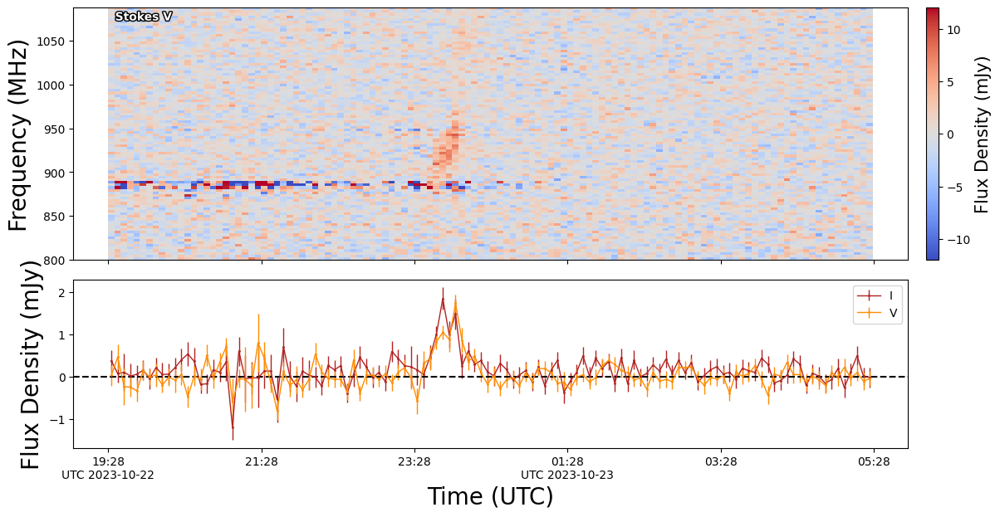

In [246]:
fig, (ax_ds, ax_lc) = plt.subplots(
    2, 1,
    figsize=(12, 6),
    height_ratios=[3, 2],
    sharex=True
)

plot_ds(ds, stokes='V', cmax=12, imag=False, fig=fig, ax=ax_ds)
plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax_lc)
ax_lc.axhline(0, c = 'black', ls = '--')

cbar = fig.axes[-1]
cbar.set_ylabel(cbar.get_ylabel(), fontsize=15)

# fig.suptitle('HD 82533 EMU Burst', fontsize=20)
plt.tight_layout()

ax_ds.set_aspect('auto')

# Get the DS position after plot_ds has added the colourbar
ds_pos = ax_ds.get_position()
lc_pos = ax_lc.get_position()

# Force LC to have exactly the same horizontal extent as DS
ax_lc.set_position([
    ds_pos.x0,
    lc_pos.y0,
    ds_pos.width,
    lc_pos.height
])

ax_ds.set_ylabel('Frequency (MHz)', fontsize=20)
ax_lc.set_ylabel('Flux Density (mJy)', fontsize=20)
ax_lc.set_xlabel('Time (UTC)',fontsize=20)

plt.savefig('thesis_figs/tyc8927-emu.pdf', dpi=300, bbox_inches='tight')
plt.show()

Text(0.5, 1.0, 'Lightcurve for HD 82533 EMU quiescent emission')

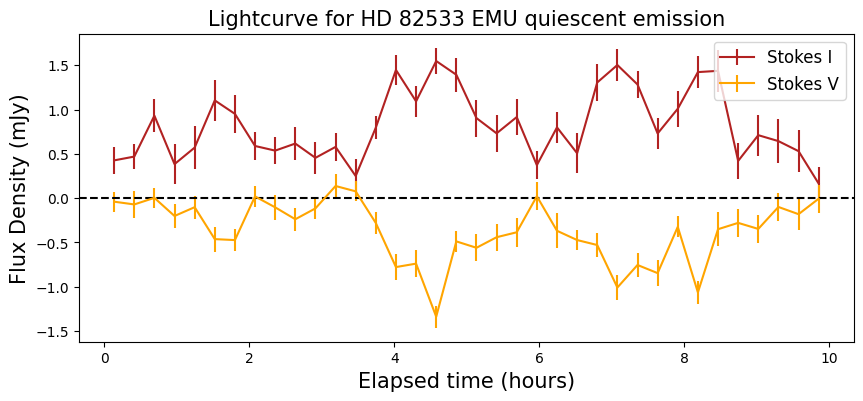

In [163]:
plt.figure(figsize = (10,4))
plt.errorbar(lc.time, lc.flux['I'], lc.flux_err['I'], c = 'firebrick', label = 'Stokes I')
plt.errorbar(lc.time, lc.flux['V'], lc.flux_err['V'], c = 'orange', label = 'Stokes V')
plt.axhline(0, c = 'black', ls = '--')
plt.xlabel('Elapsed time (hours)', fontsize=15)
plt.ylabel('Flux Density (mJy)', fontsize=15)
plt.legend(loc = 'upper right', fontsize=12)
plt.title('Lightcurve for HD 82533 EMU quiescent emission',fontsize=15)

In [202]:
np.abs(np.mean(lc.flux['V'] / (lc.flux['I'] - 1)))

np.float64(0.46332507990484373)

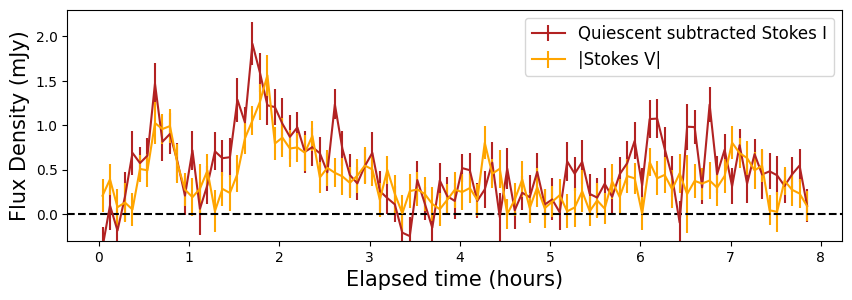

In [209]:
plt.figure(figsize = (10,3))
plt.errorbar(lc.time, lc.flux['I'] - 1, lc.flux_err['I'], c = 'firebrick', label = 'Quiescent subtracted Stokes I')
plt.errorbar(lc.time, np.abs(lc.flux['V']), lc.flux_err['V'], c = 'orange', label = '|Stokes V|')
plt.axhline(0, c = 'black', ls = '--')
plt.ylim(-0.3, 2.3)
plt.xlabel('Elapsed time (hours)', fontsize=15)
plt.ylabel('Flux Density (mJy)', fontsize=15)
plt.legend(loc = 'upper right', fontsize=12)
plt.savefig('thesis_figs/hd217344-lc.pdf', dpi=300, bbox_inches='tight')
# plt.title('Lightcurve for HD 82533 EMU quiescent emission',fontsize=15)